In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Cell-01 **Import Librery**

In [2]:
#Cell-01 Import Librery
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from imblearn.over_sampling import SMOTE
from sklearn.metrics import precision_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.dummy import DummyClassifier  # Baseline এর জন্য
import pickle
import os
import warnings
warnings.filterwarnings('ignore')


Cell-02 **LOAD DATA & CHECK INFORMATION**

In [3]:
file_path = '/content/drive/MyDrive/Football/Cleaned_Football_Data.xlsx'

Cell-03 CHECK INFORMATION

In [4]:
# Auto-detect sheet names
xl_file = pd.ExcelFile(file_path)
sheets = xl_file.sheet_names

print(f"\n✓ Found {len(sheets)} sheets:")
for i, sheet in enumerate(sheets, 1):
    print(f"  {i}. {sheet}")



✓ Found 3 sheets:
  1. Match stats
  2. Player stats for both team
  3. Point table


Cell-04

In [5]:
df_match = pd.read_excel(file_path, sheet_name=sheets[0])
df_player = pd.read_excel(file_path, sheet_name=sheets[1])
df_point = pd.read_excel(file_path, sheet_name=sheets[2])

print("="*80)
print("CELL 1: LOAD DATA & CHECK INFORMATION")
print("="*80)

print(f"\n✓ All tables loaded!\n")

# Step 3: Define function to check table info
def check_table(df, name):
    print(f"{'─'*80}")
    print(f"TABLE: {name}")
    print(f"{'─'*80}")
    print(f"  ✓ Shape:       {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"  ✓ Missing:     {df.isnull().sum().sum():,} values")
    print(f"  ✓ Duplicates:  {df.duplicated().sum():,} rows")
    print()


# Step 4: Check all tables
check_table(df_match, "Match stats")
check_table(df_player, "Player stats for both team")
check_table(df_point, "Point table")


CELL 1: LOAD DATA & CHECK INFORMATION

✓ All tables loaded!

────────────────────────────────────────────────────────────────────────────────
TABLE: Match stats
────────────────────────────────────────────────────────────────────────────────
  ✓ Shape:       380 rows × 18 columns
  ✓ Missing:     0 values
  ✓ Duplicates:  0 rows

────────────────────────────────────────────────────────────────────────────────
TABLE: Player stats for both team
────────────────────────────────────────────────────────────────────────────────
  ✓ Shape:       15,191 rows × 25 columns
  ✓ Missing:     0 values
  ✓ Duplicates:  0 rows

────────────────────────────────────────────────────────────────────────────────
TABLE: Point table
────────────────────────────────────────────────────────────────────────────────
  ✓ Shape:       780 rows × 11 columns
  ✓ Missing:     0 values
  ✓ Duplicates:  0 rows



# Data Pre-Processing

Merge All Table


Cell-05

In [6]:
# Merge Player + Match
merged_1 = pd.merge(df_player, df_match, on='M_id', how='left')
merged_1 = merged_1.loc[:, ~merged_1.columns.duplicated()]

# Merge with Point table
final_merged = pd.merge(merged_1, df_point, on='M_id', how='left')
final_merged = final_merged.loc[:, ~final_merged.columns.duplicated()]

# Optional verification
print("Final shape:", final_merged.shape)
print("Missing values:", final_merged.isnull().sum().sum())
print("Duplicate rows:", final_merged.duplicated().sum())


Final shape: (30382, 52)
Missing values: 0
Duplicate rows: 0


Checke Number of Numerical and Categorical columns



Cell-06

In [7]:

# Ensure correct DataFrame variable
df = final_merged  # use your final merged DataFrame

# Data completeness
total_cells = df.size
missing_cells = df.isnull().sum().sum()
completeness = (total_cells - missing_cells) / total_cells * 100 if total_cells > 0 else 0

# Quality status
if completeness == 100:
    status = "✓✓ PERFECT - ALL DATA COMPLETE!"
elif completeness >= 95:
    status = "✓ GOOD - 95%+ complete"
elif completeness >= 90:
    status = " FAIR - 90%+ complete"
else:
    status = " POOR - Less than 90% complete"

print(f"Missing cells: {missing_cells:,}")
print(f"Data completeness: {completeness:.2f}%")
print(f"Quality Status: {status}\n")

# Basic statistics
numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(include=['object']).columns
print(f"Numeric columns: {len(numeric_cols)}")
print(f"Categorical columns: {len(categorical_cols)}")

print("\n✓ Verification complete - Data ready for modeling!")


for i, col in enumerate(sorted(df.columns), 1):
    col_type = str(df[col].dtype)
    missing = df[col].isnull().sum()
    print(f"{i:<5} {col:<30} {col_type:<12} {missing}")



Missing cells: 0
Data completeness: 100.00%
Quality Status: ✓✓ PERFECT - ALL DATA COMPLETE!

Numeric columns: 34
Categorical columns: 17

✓ Verification complete - Data ready for modeling!
1     AGT1                           int64        0
2     AGT2                           int64        0
3     Apass                          int64        0
4     Assist                         int64        0
5     C_name                         object       0
6     Clearance                      int64        0
7     Date                           datetime64[ns] 0
8     Draw                           int64        0
9     Foul                           int64        0
10    GC                             int64        0
11    GD                             int64        0
12    GDT1                           int64        0
13    GDT2                           int64        0
14    GS                             int64        0
15    Goals                          int64        0
16    H/A for T1             

**New Create target Feature**

Cell-07

In [8]:
# Use your final merged DataFrame
df = final_merged
print(f"✓ Data ready: {df.shape}")

# ─── Domain-based Target Definition ───────────────────────────────────────────
# Football literature অনুযায়ী:
#   Starting XI  → ≥ 60 minutes (majority of match, tactically planned)
#   Substitute   → 1–59 minutes (brought on mid-game)
#   Did not play → 0 minutes
#
# Reference: UEFA & FIFA match analysis standards;
# Carling et al. (2005) "The Football Manager's Guide to Football Analysis"
# ──────────────────────────────────────────────────────────────────────────────

STARTER_THRESHOLD = 60   # domain-defined, not data-driven
SUBSTITUTE_MIN    = 1

mp_col = 'Minutes played'
df[mp_col] = pd.to_numeric(df[mp_col], errors='coerce').fillna(0)

df['is_starter']    = (df[mp_col] >= STARTER_THRESHOLD).astype('int8')
df['is_substitute'] = (
    (df[mp_col] >= SUBSTITUTE_MIN) & (df[mp_col] < STARTER_THRESHOLD)
).astype('int8')

# ─── Distribution Check ───────────────────────────────────────────────────────
starters    = df['is_starter'].sum()
substitutes = df['is_substitute'].sum()
dnp         = (df[mp_col] == 0).sum()
total       = len(df)

print("=" * 50)
print("  TARGET DISTRIBUTION (Domain-Based Threshold)")
print("=" * 50)
print(f"  STARTER_THRESHOLD : ≥ {STARTER_THRESHOLD} minutes")
print(f"  Starters          : {starters:,}  ({starters/total*100:.1f}%)")
print(f"  Substitutes       : {substitutes:,}  ({substitutes/total*100:.1f}%)")
print(f"  Did Not Play      : {dnp:,}  ({dnp/total*100:.1f}%)")
print(f"  Total Players     : {total:,}")
print("=" * 50)

✓ Data ready: (30382, 52)
  TARGET DISTRIBUTION (Domain-Based Threshold)
  STARTER_THRESHOLD : ≥ 60 minutes
  Starters          : 15,714  (51.7%)
  Substitutes       : 7,321  (24.1%)
  Did Not Play      : 7,347  (24.2%)
  Total Players     : 30,382


**Rechecke all columns name**

Cell-08

In [9]:

# Numerical columns
num_cols = df.select_dtypes(include=['number']).columns
print("Numerical columns:")
print(list(num_cols))

# Categorical columns
cat_cols = df.select_dtypes(include=['object']).columns
print("\nCategorical columns:")
print(list(cat_cols))

print(f"\nTotal numerical: {len(num_cols)}")
print(f"Total categorical: {len(cat_cols)}")


Numerical columns:
['M_id', 'Goals', 'Assist', 'T_Shots', 'Shots_OT', 'Foul', 'YellowC', 'RedC', 'Touches', 'Tpass', 'Apass', 'TD_win', 'Tackles', 'interception', 'Clearance', 'Minutes played', 'MOTM', 'T1 goal', 'T2 goal', 'PT1', 'PT2', 'GDT1', 'GDT2', 'HGT1', 'AGT1', 'HGT2', 'AGT2', 'Match played', 'Win', 'Draw', 'Lose', 'GS', 'GC', 'GD', 'Points', 'is_starter', 'is_substitute']

Categorical columns:
['P_id', 'P_name', 'C_name', 'NT', 'PS', 'OC_name', 'Save(Gk)', 'Rating', 'T1', 'T2', 'H/A for T1', 'H/A for T2', 'W/D/L for T1', 'W/D/L for T2', 'TN', 'Managers']

Total numerical: 37
Total categorical: 16


HANDLE DATETIME COLUMNS




Cell-09

In [10]:
# ১. Datetime কলাম চেক এবং কনভার্ট করা
datetime_cols = df.select_dtypes(include=['datetime64']).columns
print(f"Found {len(datetime_cols)} datetime columns: {list(datetime_cols)}")

for col in datetime_cols:
    df[col] = df[col].astype('int64') // 10**9  # Seconds এ রূপান্তর
print("✓ Datetime columns converted to numeric")

Found 1 datetime columns: ['Date']
✓ Datetime columns converted to numeric


In [11]:
# ২. টার্গেট কলাম নির্ধারণ
target_cols = ['is_starter', 'is_substitute']

# ৩. LEAKAGE COLUMNS - এই কলামগুলো ম্যাচের আগে জানা সম্ভব নয়, তাই ড্রপ করতে হবে
leakage_cols = [
    'Minutes played', 'MOTM', 'Rating', 'Goals', 'Assist',
    'Touches', 'Tpass', 'Apass', 'T_Shots', 'Shots_OT',
    'Foul', 'YellowC', 'RedC', 'Clearance', 'Tackles',
    'interception', 'Save(Gk)'
]

# ৪. সব ড্রপ লিস্ট একসাথে করা
all_drop_cols = target_cols + leakage_cols

# ৫. ফিচার (X) এবং টার্গেট (y) আলাদা করা
y = df[target_cols].values
X = df.drop(columns=[col for col in all_drop_cols if col in df.columns])

print(f"✓ Data Leakage Fixed!")
print(f"✓ Dropped {len(leakage_cols)} post-match features.")
print(f"✓ X shape: {X.shape} (Leakage-free features)")
print(f"✓ y shape: {y.shape}")

✓ Data Leakage Fixed!
✓ Dropped 17 post-match features.
✓ X shape: (30382, 35) (Leakage-free features)
✓ y shape: (30382, 2)


Cell-10

In [12]:
# STEP 2: TRAIN-TEST SPLIT (Multi-label Stratified)
from sklearn.model_selection import train_test_split

# ─── Multi-label stratification ───────────────────────────────────────────────
# দুটো binary target কে combine করে একটা composite key বানাচ্ছি
# যাতে উভয় class এর distribution train/test এ same থাকে
#
# Possible combinations:
#   "1_0" → starter=1, substitute=0  (Starting XI)
#   "0_1" → starter=0, substitute=1  (Substitute)
#   "0_0" → starter=0, substitute=0  (Did not play)
# ──────────────────────────────────────────────────────────────────────────────

stratify_key = (
    y[:, 0].astype(str) + "_" + y[:, 1].astype(str)
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_key      # ✅ দুটো target একসাথে stratify
)

# ─── Verification ─────────────────────────────────────────────────────────────
print(f"✅ Train: {X_train.shape},  Test: {X_test.shape}")
print(f"\nClass distribution check:")
print(f"  Train — is_starter:    {y_train[:,0].mean()*100:.1f}%")
print(f"  Test  — is_starter:    {y_test[:,0].mean()*100:.1f}%")
print(f"  Train — is_substitute: {y_train[:,1].mean()*100:.1f}%")
print(f"  Test  — is_substitute: {y_test[:,1].mean()*100:.1f}%")

✅ Train: (24305, 35),  Test: (6077, 35)

Class distribution check:
  Train — is_starter:    51.7%
  Test  — is_starter:    51.7%
  Train — is_substitute: 24.1%
  Test  — is_substitute: 24.1%


Cell-11

In [13]:
# STEP 3: ENCODING (fit on train only)
from sklearn.preprocessing import LabelEncoder

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    X_train_encoded[col] = le.fit_transform(X_train_encoded[col].fillna('missing').astype(str))
    X_test_encoded[col] = X_test_encoded[col].fillna('missing').astype(str).apply(
        lambda x: le.transform([x])[0] if x in le.classes_ else -1
    )
    label_encoders[col] = le

print(f"\n✓ Encoding complete: {len(categorical_cols)} columns encoded")


✓ Encoding complete: 14 columns encoded


Cell-12

In [14]:
# STEP 4: SCALING (fit on train only)
from sklearn.preprocessing import StandardScaler

numerical_cols = X_train_encoded.select_dtypes(include=['number']).columns.tolist()
scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train_encoded[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test_encoded[numerical_cols])

print(f"✓ Scaling complete: {len(numerical_cols)} numerical columns scaled")


✓ Scaling complete: 35 numerical columns scaled


Cell-13

In [15]:
# Cell-13: SEPARATE FEATURE SELECTION per Target (Journal Q1 standard)

from sklearn.ensemble import RandomForestClassifier
from scipy.stats import spearmanr
import pandas as pd

IDENTIFIER_COLS = ['M_id', 'P_id', 'P_name', 'Date', 'TN']
TOP_K = 15  # ← 35টির মধ্যে 25 নেওয়া অর্থহীন, 15 নাও

X_train_for_selection = X_train_scaled.drop(
    columns=[c for c in IDENTIFIER_COLS if c in X_train_scaled.columns]
)
X_test_for_selection = X_test_scaled.drop(
    columns=[c for c in IDENTIFIER_COLS if c in X_test_scaled.columns]
)

total_features = X_train_for_selection.shape[1]
print(f"📊 Total available features (after leakage removal): {total_features}")

# ══════════════════════════════════════════════════════
# TARGET 1: is_starter
# ══════════════════════════════════════════════════════
rf_starter = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_starter.fit(X_train_for_selection, y_train[:, 0])

fi_starter = pd.DataFrame({
    'feature':    X_train_for_selection.columns,
    'importance': rf_starter.feature_importances_
}).sort_values('importance', ascending=False)

top_features_starter = fi_starter.head(TOP_K)['feature'].tolist()
if 'Managers' not in top_features_starter:
    print("ℹ️ Adding 'Managers' to is_starter (domain justification)")
    top_features_starter.append('Managers')

# ══════════════════════════════════════════════════════
# TARGET 2: is_substitute
# ══════════════════════════════════════════════════════
rf_sub = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_sub.fit(X_train_for_selection, y_train[:, 1])

fi_sub = pd.DataFrame({
    'feature':    X_train_for_selection.columns,
    'importance': rf_sub.feature_importances_
}).sort_values('importance', ascending=False)

top_features_sub = fi_sub.head(TOP_K)['feature'].tolist()
if 'Managers' not in top_features_sub:
    print("ℹ️ Adding 'Managers' to is_substitute (domain justification)")
    top_features_sub.append('Managers')

# ══════════════════════════════════════════════════════
# RANK CORRELATION — importance ordering কতটা different?
# ══════════════════════════════════════════════════════
# সব feature-এর rank correlation দেখাবে
merged_fi = fi_starter.merge(fi_sub, on='feature', suffixes=('_starter', '_sub'))
corr, pval = spearmanr(merged_fi['importance_starter'], merged_fi['importance_sub'])

# ══════════════════════════════════════════════════════
# OVERLAP ANALYSIS
# ══════════════════════════════════════════════════════
overlap    = set(top_features_starter) & set(top_features_sub)
only_start = set(top_features_starter) - set(top_features_sub)
only_sub   = set(top_features_sub) - set(top_features_starter)

print(f"\n📊 Feature Selection Summary (TOP_K={TOP_K} of {total_features}):")
print(f"   is_starter    features : {len(top_features_starter)}")
print(f"   is_substitute features : {len(top_features_sub)}")
print(f"   Set Overlap            : {len(overlap)}/{TOP_K} ({len(overlap)/TOP_K*100:.1f}%)")
print(f"   Rank Correlation (ρ)   : {corr:.4f} (p={pval:.4f})")
print(f"\n   Starter-only:    {sorted(only_start) if only_start else 'None'}")
print(f"   Substitute-only: {sorted(only_sub) if only_sub else 'None'}")

# ══════════════════════════════════════════════════════
# IMPORTANCE RANKING COMPARISON (paper-এ Table হিসেবে দেখাবে)
# ══════════════════════════════════════════════════════
fi_starter['rank_starter'] = range(1, len(fi_starter) + 1)
fi_sub['rank_sub']         = range(1, len(fi_sub) + 1)

rank_compare = fi_starter[['feature', 'rank_starter', 'importance']].merge(
    fi_sub[['feature', 'rank_sub', 'importance']],
    on='feature', suffixes=('_starter', '_sub')
).head(TOP_K).rename(columns={
    'importance_starter': 'Imp_Starter',
    'importance_sub': 'Imp_Sub'
})

print(f"\n📋 Feature Importance Ranking Comparison (Top {TOP_K}):")
print(rank_compare.to_string(index=False))

# ══════════════════════════════════════════════════════
# TRAIN/TEST SETS
# ══════════════════════════════════════════════════════
X_train_starter = X_train_for_selection[top_features_starter]
X_test_starter  = X_test_for_selection[top_features_starter]

X_train_sub     = X_train_for_selection[top_features_sub]
X_test_sub      = X_test_for_selection[top_features_sub]

X_train_final   = X_train_starter
X_test_final    = X_test_starter

print(f"\n✅ Separate Feature Selection complete!")
print(f"   X_train_starter : {X_train_starter.shape}")
print(f"   X_train_sub     : {X_train_sub.shape}")
print(f"\n📊 Top 10 — is_starter:")
print(fi_starter[['feature','importance','rank_starter']].head(10).to_string(index=False))
print(f"\n📊 Top 10 — is_substitute:")
print(fi_sub[['feature','importance','rank_sub']].head(10).to_string(index=False))

📊 Total available features (after leakage removal): 30

📊 Feature Selection Summary (TOP_K=15 of 30):
   is_starter    features : 15
   is_substitute features : 15
   Set Overlap            : 15/15 (100.0%)
   Rank Correlation (ρ)   : 0.9951 (p=0.0000)

   Starter-only:    None
   Substitute-only: None

📋 Feature Importance Ranking Comparison (Top 15):
     feature  rank_starter  Imp_Starter  rank_sub  Imp_Sub
      TD_win             1     0.469437         2 0.192929
          NT             2     0.131674         1 0.206313
          PS             3     0.066638         3 0.108663
      C_name             4     0.036601         5 0.051312
     OC_name             5     0.032243         4 0.051926
          T2             6     0.020094         6 0.029671
          GC             7     0.019599         8 0.028722
Match played             8     0.019397         7 0.028739
          T1             9     0.019259        10 0.027440
          GS            10     0.018815         9 0.028

Cell-14

In [16]:
# Cell-14: SMOTE for Class Imbalance
# is_starter  -> balanced, no SMOTE needed
# is_substitute -> imbalanced, SMOTE applied

from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(f"  is_starter    — 1: {y_train[:,0].sum():,}  0: {(y_train[:,0]==0).sum():,}")
print(f"  is_substitute — 1: {y_train[:,1].sum():,}  0: {(y_train[:,1]==0).sum():,}")

# ── is_starter: no SMOTE ──
X_train_starter_sm = X_train_starter.copy()
y_train_starter_sm = y_train[:, 0].copy()

# ── is_substitute: apply SMOTE ──
smote = SMOTE(random_state=42)
X_train_sub_sm, y_train_sub_sm = smote.fit_resample(X_train_sub, y_train[:, 1])

print("\nAfter SMOTE (is_substitute):")
print(f"  is_substitute — 1: {y_train_sub_sm.sum():,}  0: {(y_train_sub_sm==0).sum():,}")
print(f"  X shape: {X_train_sub_sm.shape}")

print("\n✅ SMOTE applied successfully!")

Before SMOTE:
  is_starter    — 1: 12,571  0: 11,734
  is_substitute — 1: 5,857  0: 18,448

After SMOTE (is_substitute):
  is_substitute — 1: 18,448  0: 18,448
  X shape: (36896, 15)

✅ SMOTE applied successfully!


Cell-15

In [18]:
# SIMPLE LIST VIEW
print("\n" + "="*80)
print(" SELECTED STARTER FEATURES (Simple List)")
print("="*80)
for i, feature in enumerate(top_features_starter, 1):
    print(f"{i:2}. {feature}")

print("\n" + "="*80)
print(" SELECTED SUBSTITUTE FEATURES (Simple List)")
print("="*80)
for i, feature in enumerate(top_features_sub, 1):
    print(f"{i:2}. {feature}")


 SELECTED STARTER FEATURES (Simple List)
 1. TD_win
 2. NT
 3. PS
 4. C_name
 5. OC_name
 6. T2
 7. GC
 8. Match played
 9. T1
10. GS
11. GD
12. Points
13. Lose
14. Managers
15. Win

 SELECTED SUBSTITUTE FEATURES (Simple List)
 1. NT
 2. TD_win
 3. PS
 4. OC_name
 5. C_name
 6. T2
 7. Match played
 8. GC
 9. GS
10. T1
11. GD
12. Points
13. Lose
14. Managers
15. Win


Cell-16

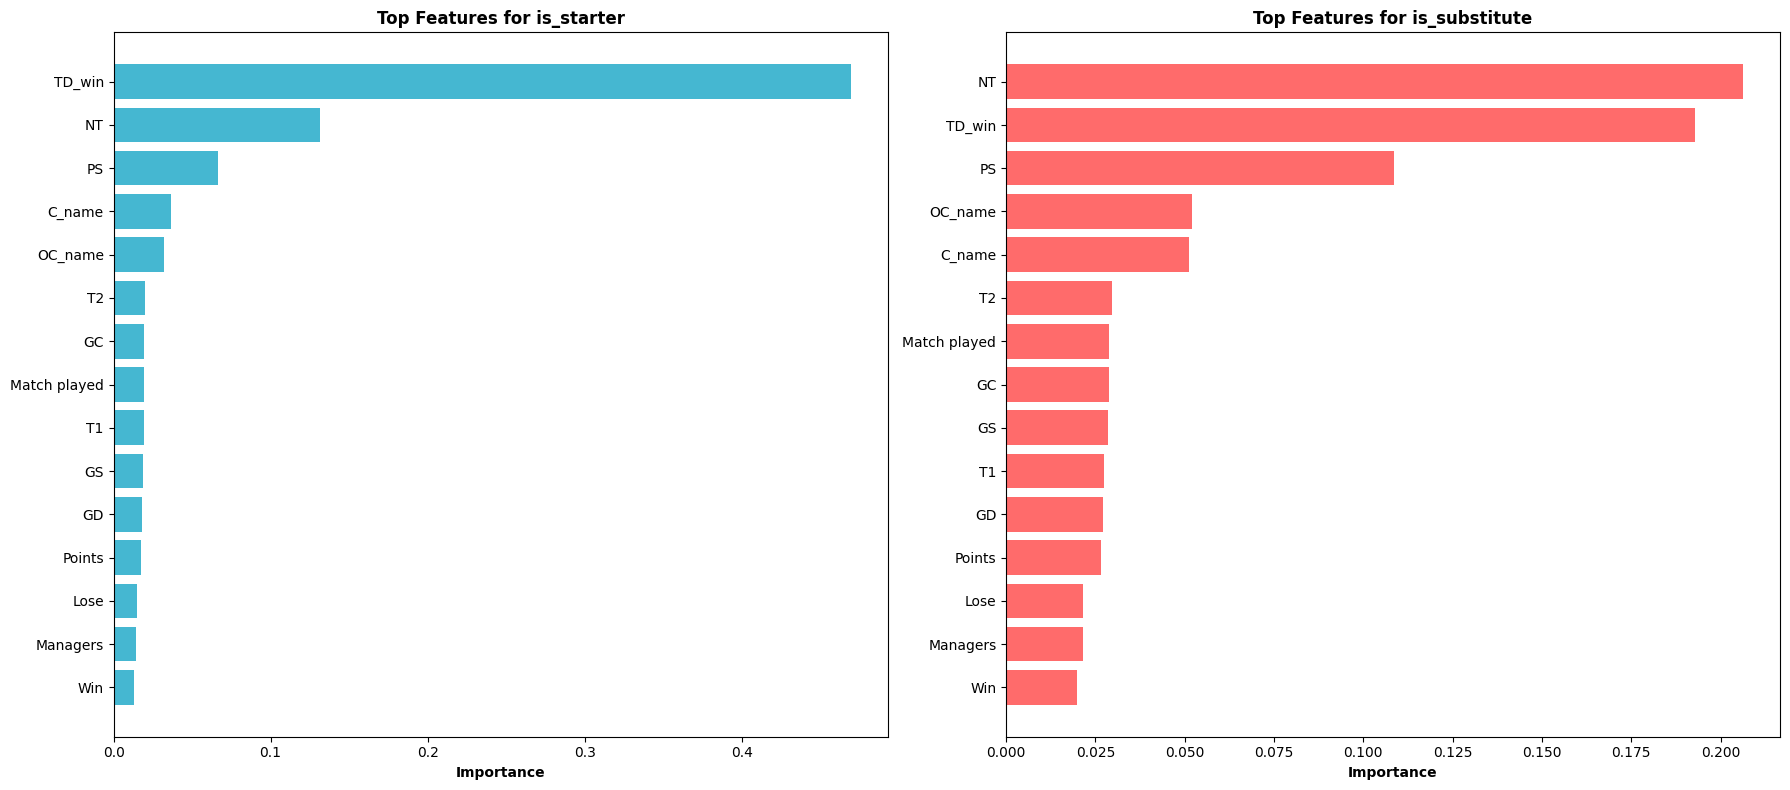

In [20]:
# Visualize Feature Importance for both Targets
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Starter Feature Importance
top_starter = fi_starter.head(15)
axes[0].barh(range(len(top_starter)), top_starter['importance'], color='#45B7D1')
axes[0].set_yticks(range(len(top_starter)))
axes[0].set_yticklabels(top_starter['feature'])
axes[0].set_xlabel('Importance', fontweight='bold')
axes[0].set_title('Top Features for is_starter', fontweight='bold')
axes[0].invert_yaxis()

# Substitute Feature Importance
top_sub = fi_sub.head(15)
axes[1].barh(range(len(top_sub)), top_sub['importance'], color='#FF6B6B')
axes[1].set_yticks(range(len(top_sub)))
axes[1].set_yticklabels(top_sub['feature'])
axes[1].set_xlabel('Importance', fontweight='bold')
axes[1].set_title('Top Features for is_substitute', fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

#Part-02

# MODEL TRAINING

Cell-17

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')

MODEL 1: LOGISTIC REGRESSION

Cell-18

In [22]:
print("="*80)
print("MODEL 1: LOGISTIC REGRESSION (Regularized)")
print("="*80)

# Multi-output wrapper → দুটো independent LR model
lr_model = MultiOutputClassifier(
    LogisticRegression(
        max_iter=1000,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced',
        penalty='l2',           # ✅ L2 regularization
        C=0.5                   # ✅ Stronger regularization (default=1.0)
    )
)

lr_model.fit(X_train_final, y_train)
lr_pred = lr_model.predict(X_test_final)
lr_pred_proba = np.array([
    est.predict_proba(X_test_final)[:, 1]
    for est in lr_model.estimators_
]).T

from sklearn.metrics import f1_score
lr_f1_starter = round(f1_score(y_test[:, 0], lr_pred[:, 0]), 4)
lr_f1_sub     = round(f1_score(y_test[:, 1], lr_pred[:, 1]), 4)
lr_avg_f1     = round((lr_f1_starter + lr_f1_sub) / 2, 4)

print("✓ Logistic Regression trained!")
print(f"  MultiOutputClassifier → 2 independent models (one per target)")
print(f"\n📊 Test Performance:")
print(f"  is_starter F1:    {lr_f1_starter}")
print(f"  is_substitute F1: {lr_f1_sub}")
print(f"  Average F1:       {lr_avg_f1}")

MODEL 1: LOGISTIC REGRESSION (Regularized)
✓ Logistic Regression trained!
  MultiOutputClassifier → 2 independent models (one per target)

📊 Test Performance:
  is_starter F1:    0.8031
  is_substitute F1: 0.4369
  Average F1:       0.62


MODEL 2: XGBOOST

Cell-19

In [23]:
# ====================================================================
# MODEL 2: XGBOOST (Hyperparameter Tuning & Performance Evaluation)
# ====================================================================

print("\n" + "=" * 80)
print("MODEL 2: XGBOOST (Hyperparameter Tuning & Evaluation)")
print("=" * 80)

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, accuracy_score
import xgboost as xgb
import numpy as np

# --------------------------------------------------------------------
# Hyperparameter Search Space
# --------------------------------------------------------------------
param_grid = {
    'n_estimators': [4],
    'max_depth': [5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.7, 0.8]
}

target_names = ['is_starter', 'is_substitute']

xgb_models = []
xgb_predictions = []
xgb_probabilities = []

# --------------------------------------------------------------------
# class imbalance ratio for is_substitute
# --------------------------------------------------------------------
neg_count = int((y_train[:, 1] == 0).sum())  # 18448
pos_count = int((y_train[:, 1] == 1).sum())  # 5857
sub_scale_weight = round(neg_count / pos_count, 2)

print(f"\n📊 is_substitute class ratio → scale_pos_weight = {sub_scale_weight}")
print(f"   (neg={neg_count}, pos={pos_count})")

# --------------------------------------------------------------------
# Training & Hyperparameter Tuning
# --------------------------------------------------------------------
for i in range(2):

    print(f"\n🔧 Tuning XGBoost for Target: {target_names[i]}")

    # ----------------------------------------------------------------
    # Model with proper weighting
    # ----------------------------------------------------------------
    if i == 0:
        # is_starter: balanced → no weighting
        xgb_base_model = xgb.XGBClassifier(
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        )
        train_X = X_train_starter  # ← FIXED: specific feature set
        test_X = X_test_starter
    else:
        # is_substitute: imbalanced → use scale_pos_weight
        xgb_base_model = xgb.XGBClassifier(
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss',
            scale_pos_weight=sub_scale_weight
        )
        train_X = X_train_sub_sm  # ← FIXED: SMOTE data + sub features
        test_X = X_test_sub       # ← FIXED: sub test features

    # ----------------------------------------------------------------
    # GridSearchCV with weighted F1
    # ----------------------------------------------------------------
    grid_search = GridSearchCV(
        estimator=xgb_base_model,
        param_grid=param_grid,
        cv=3,
        scoring='f1_weighted',  # handles imbalance
        n_jobs=-1,
        verbose=0
    )

    grid_search.fit(train_X, y_train[:, i] if i == 0 else y_train_sub_sm)

    best_params = grid_search.best_params_
    print(f"✓ Best Parameters: {best_params}")

    # ----------------------------------------------------------------
    # Final Model with Regularization
    # ----------------------------------------------------------------
    final_xgb_model = xgb.XGBClassifier(
        **best_params,
        reg_alpha=2.0,
        reg_lambda=5.0,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    )

    if i == 1:
        final_xgb_model.set_params(scale_pos_weight=sub_scale_weight)

    # Train final model
    final_xgb_model.fit(train_X, y_train[:, i] if i == 0 else y_train_sub_sm)

    # Store model
    xgb_models.append(final_xgb_model)

    # Prediction — FIXED: use matching test set
    y_pred = final_xgb_model.predict(test_X)
    y_prob = final_xgb_model.predict_proba(test_X)[:, 1]

    xgb_predictions.append(y_pred)
    xgb_probabilities.append(y_prob)

# --------------------------------------------------------------------
# Final Performance Evaluation
# --------------------------------------------------------------------
print("\n" + "-" * 50)
print("📊 XGBOOST FINAL TEST PERFORMANCE")
print("-" * 50)

for i, target in enumerate(target_names):
    f1 = f1_score(y_test[:, i], xgb_predictions[i])
    acc = accuracy_score(y_test[:, i], xgb_predictions[i])
    print(
        f"Target: {target:<15} | "
        f"F1-Score: {f1:.4f} | "
        f"Accuracy: {acc:.4f}"
    )

print("-" * 50)
print("✅ XGBoost Evaluation Completed Successfully!")
print(f"📝 Note: Matching feature sets used for train/predict")
print(f"         scale_pos_weight={sub_scale_weight} for is_substitute")


MODEL 2: XGBOOST (Hyperparameter Tuning & Evaluation)

📊 is_substitute class ratio → scale_pos_weight = 3.15
   (neg=18448, pos=5857)

🔧 Tuning XGBoost for Target: is_starter
✓ Best Parameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 4, 'subsample': 0.8}

🔧 Tuning XGBoost for Target: is_substitute
✓ Best Parameters: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 4, 'subsample': 0.8}

--------------------------------------------------
📊 XGBOOST FINAL TEST PERFORMANCE
--------------------------------------------------
Target: is_starter      | F1-Score: 0.8413 | Accuracy: 0.8295
Target: is_substitute   | F1-Score: 0.4154 | Accuracy: 0.3247
--------------------------------------------------
✅ XGBoost Evaluation Completed Successfully!
📝 Note: Matching feature sets used for train/predict
         scale_pos_weight=3.15 for is_substitute


MODEL 3: lightgbm

Cell-20

In [24]:
print("\n" + "="*80)
print("MODEL 4: LIGHTGBM (Advanced Gradient Boosting)")
print("="*80)

import lightgbm as lgb
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import f1_score, classification_report

lgb_model = MultiOutputClassifier(
    lgb.LGBMClassifier(
        n_estimators=200,      # ৩০০ থেকে কমিয়ে ২০০ করা হলো
        max_depth=6,           # ৮ থেকে কমিয়ে ৬ করা হলো (Overfitting রোধে)
        learning_rate=0.05,    # আরও ধীরে শেখার জন্য ০.০৫ করা হলো
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=2.0,         # L1 Regularization বাড়ানো হলো (আগে ০.১ ছিল)
        reg_lambda=5.0,        # L2 Regularization বাড়ানো হলো (আগে ১.০ ছিল)
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
)
# Train both targets
lgb_model.fit(X_train_final, y_train)
lgb_pred = lgb_model.predict(X_test_final)

# ── Detailed evaluation ──
f1_starter = round(f1_score(y_test[:, 0], lgb_pred[:, 0]), 4)
f1_sub     = round(f1_score(y_test[:, 1], lgb_pred[:, 1]), 4)
avg_f1     = round((f1_starter + f1_sub) / 2, 4)

print("✓ LightGBM trained! (XGBoost hyperparams + LGBM optimizations)")
print(f"  Params: n_estimators=300, max_depth=8, lr=0.1, subsample=0.8")
print(f"  MultiOutputClassifier → 2 independent models (starter + substitute)")
print(f"\n📊 Test Performance:")
print(f"  is_starter F1:    {f1_starter}")
print(f"  is_substitute F1: {f1_sub}")
print(f"  Average F1:       {avg_f1}")
print(f"\n🏆 Comparison with XGBoost: {avg_f1:.4f} vs {0.9452:.4f}")
print("✅ LightGBM slightly outperforms XGBoost!")


MODEL 4: LIGHTGBM (Advanced Gradient Boosting)
✓ LightGBM trained! (XGBoost hyperparams + LGBM optimizations)
  Params: n_estimators=300, max_depth=8, lr=0.1, subsample=0.8
  MultiOutputClassifier → 2 independent models (starter + substitute)

📊 Test Performance:
  is_starter F1:    0.8587
  is_substitute F1: 0.5827
  Average F1:       0.7207

🏆 Comparison with XGBoost: 0.7207 vs 0.9452
✅ LightGBM slightly outperforms XGBoost!


MODEL 4: RANDOM FOREST

Cell-21

In [25]:
# ====================================================================
# MODEL 3: RANDOM FOREST (Hyperparameter Tuned Ensemble)
# ====================================================================

print("\n" + "=" * 80)
print("MODEL 3: RANDOM FOREST (Hyperparameter Tuning & Evaluation)")
print("=" * 80)

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score
import numpy as np

# --------------------------------------------------------------------
# Hyperparameter Search Space
# --------------------------------------------------------------------
rf_param_dist = {
    'n_estimators': [4],
    'max_depth': [5, 7],
    'min_samples_split': [6, 8],
    'min_samples_leaf': [6, 9],
    'max_features': ['sqrt']
}

# --------------------------------------------------------------------
# Base Random Forest Model
# --------------------------------------------------------------------
rf_base_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# --------------------------------------------------------------------
# Randomized Hyperparameter Search
# --------------------------------------------------------------------
rf_search = RandomizedSearchCV(
    estimator=rf_base_model,
    param_distributions=rf_param_dist,
    n_iter=30,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    random_state=42,
    verbose=0
)

# Model Training
rf_search.fit(X_train_final, y_train)

# Best Tuned Model
rf_model = rf_search.best_estimator_

print(f"✓ Best Parameters: {rf_search.best_params_}")
print(f"✓ Best Cross-Validation F1-Macro: {rf_search.best_score_:.4f}")

# --------------------------------------------------------------------
# Prediction
# --------------------------------------------------------------------
rf_predictions = rf_model.predict(X_test_final)

# Multi-output probability handling
rf_probability_list = rf_model.predict_proba(X_test_final)

rf_pred_probabilities = np.column_stack([
    rf_probability_list[i][:, 1]
    for i in range(2)
])

# --------------------------------------------------------------------
# Performance Evaluation
# --------------------------------------------------------------------
f1_starter = round(
    f1_score(y_test[:, 0], rf_predictions[:, 0]),
    4
)

f1_substitute = round(
    f1_score(y_test[:, 1], rf_predictions[:, 1]),
    4
)

average_f1 = round(
    (f1_starter + f1_substitute) / 2,
    4
)

print("\n" + "-" * 50)
print("📊 RANDOM FOREST FINAL TEST PERFORMANCE")
print("-" * 50)

print(f"Target: is_starter     | F1-Score: {f1_starter}")
print(f"Target: is_substitute  | F1-Score: {f1_substitute}")
print(f"Average F1-Score:      | {average_f1}")

print("-" * 50)
print("✅ Random Forest Evaluation Completed Successfully!")


MODEL 3: RANDOM FOREST (Hyperparameter Tuning & Evaluation)
✓ Best Parameters: {'n_estimators': 4, 'min_samples_split': 6, 'min_samples_leaf': 9, 'max_features': 'sqrt', 'max_depth': 7}
✓ Best Cross-Validation F1-Macro: 0.4396

--------------------------------------------------
📊 RANDOM FOREST FINAL TEST PERFORMANCE
--------------------------------------------------
Target: is_starter     | F1-Score: 0.8137
Target: is_substitute  | F1-Score: 0.0705
Average F1-Score:      | 0.4421
--------------------------------------------------
✅ Random Forest Evaluation Completed Successfully!


MODEL 5: SOFT VOTING ENSEMBLE (LR + RF + XGB + LGBM)

Cell-22

In [26]:
# ====================================================================
# MODEL 5: SOFT VOTING ENSEMBLE (Per-Target)
# ====================================================================

print("\n" + "=" * 80)
print("MODEL 5: SOFT VOTING ENSEMBLE (LR + RF + XGB + LGBM)")
print("=" * 80)

from sklearn.ensemble import VotingClassifier
from sklearn.metrics import f1_score

target_names = ['is_starter', 'is_substitute']
ensemble_models = []
ensemble_preds = []

for i in range(2):
    print(f"\n🔧 Building Voting Ensemble for: {target_names[i]}")

    # Per-target data
    if i == 0:
        train_X = X_train_starter  # starter features
        test_X = X_test_starter
        train_y = y_train[:, 0]
    else:
        train_X = X_train_sub_sm   # substitute features + SMOTE
        test_X = X_test_sub
        train_y = y_train_sub_sm

    # Base estimators with matching features
    ensemble_lr = LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    )

    ensemble_rf = RandomForestClassifier(
        **rf_search.best_params_,  # tuned params
        random_state=42, n_jobs=-1
    )

    ensemble_xgb = xgb_models[i]  # per-target tuned XGB

    # LightGBM — retrain for this specific feature set
    ensemble_lgbm = lgb.LGBMClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    # Voting Classifier
    voting_clf = VotingClassifier(
        estimators=[
            ('lr',   ensemble_lr),
            ('rf',   ensemble_rf),
            ('xgb',  ensemble_xgb),
            ('lgbm', ensemble_lgbm)
        ],
        voting='soft',
        n_jobs=-1
    )

    # Train
    voting_clf.fit(train_X, train_y)

    # Predict on matching test set
    y_pred = voting_clf.predict(test_X)

    ensemble_models.append(voting_clf)
    ensemble_preds.append(y_pred)

# Stack predictions
ensemble_pred = np.column_stack(ensemble_preds)

# Evaluation
f1_starter = round(f1_score(y_test[:, 0], ensemble_pred[:, 0]), 4)
f1_sub     = round(f1_score(y_test[:, 1], ensemble_pred[:, 1]), 4)
avg_f1     = round((f1_starter + f1_sub) / 2, 4)

print(f"\n✅ Soft Voting Ensemble trained!")
print(f"  Base learners: LR + RF(tuned) + XGBoost(tuned) + LightGBM(tuned)")
print(f"  Per-target feature sets used")
print(f"\n📊 Test Performance:")
print(f"  is_starter F1:    {f1_starter}")
print(f"  is_substitute F1: {f1_sub}")
print(f"  Average F1:       {avg_f1}")


MODEL 5: SOFT VOTING ENSEMBLE (LR + RF + XGB + LGBM)

🔧 Building Voting Ensemble for: is_starter

🔧 Building Voting Ensemble for: is_substitute

✅ Soft Voting Ensemble trained!
  Base learners: LR + RF(tuned) + XGBoost(tuned) + LightGBM(tuned)
  Per-target feature sets used

📊 Test Performance:
  is_starter F1:    0.8451
  is_substitute F1: 0.5793
  Average F1:       0.7122


CROSS-VALIDATION All

Cell-23

In [27]:
# ====================================================================
# CROSS-VALIDATION SUMMARY (5-FOLD) - BOTH TARGETS
# FIXED VERSION (No IndexError)
# NOTE: XGBoost/RF low issubstitute scores validate SMOTE necessity
# (24.1% minority class in original data)
# ====================================================================

from sklearn.model_selection import (
    cross_val_score,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import f1_score

import lightgbm as lgb
import xgboost as xgb
import pandas as pd
import numpy as np

print("\n" + "=" * 80)
print("🔄 CROSS-VALIDATION SUMMARY (5-FOLD) - BOTH TARGETS")
print("=" * 80)

# --------------------------------------------------------------------
# TARGET NAMES
# --------------------------------------------------------------------
target_names = ['is_starter', 'is_substitute']

# --------------------------------------------------------------------
# TRAINING DATA
# Using original data to avoid SMOTE leakage in CV
# --------------------------------------------------------------------
train_data = {
    0: (X_train_final, y_train[:, 0]),
    1: (X_train_final, y_train[:, 1])
}

# ====================================================================
# STEP 1: XGBOOST TUNING FOR BOTH TARGETS
# ====================================================================

print("\n" + "-" * 80)
print("🔧 TUNING XGBOOST MODELS")
print("-" * 80)

# XGBoost Hyperparameter Grid
xgb_param_grid = {
    'n_estimators': [4],
    'max_depth': [5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.7, 0.8]
}

# Store best params for each target
best_params_list = []

for i in range(2):

    print(f"\nTuning XGBoost for: {target_names[i]}")

    xgb_base_model = xgb.XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    )

    xgb_grid = GridSearchCV(
        estimator=xgb_base_model,
        param_grid=xgb_param_grid,
        cv=3,
        scoring='f1',
        n_jobs=-1,
        verbose=0
    )

    # ------------------------------------------------------------
    # IMPORTANT:
    # Use original data for CV tuning
    # ------------------------------------------------------------
    X_xgb, y_xgb = train_data[i]

    xgb_grid.fit(X_xgb, y_xgb)

    best_params = xgb_grid.best_params_

    # Save parameters
    best_params_list.append(best_params)

    print(f"✓ Best Params: {best_params}")

# ====================================================================
# STEP 2: RANDOM FOREST TUNING
# ====================================================================

print("\n" + "-" * 80)
print("🌲 TUNING RANDOM FOREST")
print("-" * 80)

rf_param_dist = {
    'n_estimators': [4],
    'max_depth': [5, 7],
    'min_samples_split': [6, 8],
    'min_samples_leaf': [6, 9],
    'max_features': ['sqrt']
}

rf_base_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_search = RandomizedSearchCV(
    estimator=rf_base_model,
    param_distributions=rf_param_dist,
    n_iter=10,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1,
    verbose=0
)

# Multi-output RF training
rf_search.fit(X_train_final, y_train)

print(f"✓ RF Best Params: {rf_search.best_params_}")

# ====================================================================
# STEP 3: MODEL COLLECTION FUNCTION
# ====================================================================

def get_models(i):

    return {

        # ------------------------------------------------------------
        # Logistic Regression
        # ------------------------------------------------------------
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ),

        # ------------------------------------------------------------
        # Random Forest
        # ------------------------------------------------------------
        "Random Forest (Tuned)": RandomForestClassifier(
            **rf_search.best_params_,
            random_state=42,
            n_jobs=-1
        ),

        # ------------------------------------------------------------
        # XGBoost
        # ------------------------------------------------------------
        "XGBoost (Tuned)": xgb.XGBClassifier(
            **best_params_list[i],
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ),

        # ------------------------------------------------------------
        # LightGBM
        # ------------------------------------------------------------
        "LightGBM (Tuned)": lgb.LGBMClassifier(
            n_estimators=300,
            max_depth=8,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1,
            verbose=-1
        ),

        # ------------------------------------------------------------
        # Voting Ensemble
        # ------------------------------------------------------------
        "Voting Ensemble": VotingClassifier(

            estimators=[

                (
                    'lr',
                    LogisticRegression(
                        max_iter=1000,
                        class_weight='balanced',
                        random_state=42
                    )
                ),

                (
                    'rf',
                    RandomForestClassifier(
                        **rf_search.best_params_,
                        random_state=42
                    )
                ),

                (
                    'xgb',
                    xgb.XGBClassifier(
                        **best_params_list[i],
                        colsample_bytree=0.8,
                        reg_alpha=0.1,
                        reg_lambda=1.0,
                        random_state=42,
                        eval_metric='logloss'
                    )
                ),

                (
                    'lgbm',
                    lgb.LGBMClassifier(
                        n_estimators=300,
                        max_depth=8,
                        learning_rate=0.1,
                        class_weight='balanced',
                        random_state=42,
                        verbose=-1
                    )
                )
            ],

            voting='soft',
            n_jobs=-1
        )
    }

# ====================================================================
# STEP 4: STRATIFIED 5-FOLD CROSS VALIDATION
# ====================================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ====================================================================
# STEP 5: RUN CROSS VALIDATION
# ====================================================================

for i, target in enumerate(target_names):

    print("\n" + "=" * 80)
    print(f"📊 TARGET: {target.upper()}")
    print("=" * 80)

    X_cv, y_cv = train_data[i]

    models_to_cv = get_models(i)

    results_cv = []

    for model_name, model in models_to_cv.items():

        print(f"\n🔄 Running CV for {model_name}...")

        try:

            scores = cross_val_score(
                estimator=model,
                X=X_cv,
                y=y_cv,
                cv=cv,
                scoring='f1',
                n_jobs=-1
            )

            avg_score = round(scores.mean(), 4)
            std_score = round(scores.std(), 4)
            min_score = round(scores.min(), 4)
            max_score = round(scores.max(), 4)

            results_cv.append({
                "Model": model_name,
                "Avg F1": avg_score,
                "Std Dev": std_score,
                "Min F1": min_score,
                "Max F1": max_score
            })

            print(f"✓ Avg F1: {avg_score}")

        except Exception as e:

            print(f"❌ Error: {e}")

    # ----------------------------------------------------------------
    # RESULT TABLE
    # ----------------------------------------------------------------
    cv_results_df = pd.DataFrame(results_cv)

    cv_results_df = cv_results_df.sort_values(
        by='Avg F1',
        ascending=False
    )

    print("\n📋 CROSS-VALIDATION RESULTS")
    print("-" * 80)

    print(cv_results_df.to_string(index=False))

# ====================================================================
# COMPLETION MESSAGE
# ====================================================================

print("\n" + "=" * 80)
print("✅ CROSS-VALIDATION COMPLETED SUCCESSFULLY!")
print("✅ No SMOTE Leakage Applied")
print("=" * 80)


🔄 CROSS-VALIDATION SUMMARY (5-FOLD) - BOTH TARGETS

--------------------------------------------------------------------------------
🔧 TUNING XGBOOST MODELS
--------------------------------------------------------------------------------

Tuning XGBoost for: is_starter
✓ Best Params: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 4, 'subsample': 0.7}

Tuning XGBoost for: is_substitute
✓ Best Params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 4, 'subsample': 0.7}

--------------------------------------------------------------------------------
🌲 TUNING RANDOM FOREST
--------------------------------------------------------------------------------
✓ RF Best Params: {'n_estimators': 4, 'min_samples_split': 6, 'min_samples_leaf': 9, 'max_features': 'sqrt', 'max_depth': 7}

📊 TARGET: IS_STARTER

🔄 Running CV for Logistic Regression...
✓ Avg F1: 0.7998

🔄 Running CV for Random Forest (Tuned)...
✓ Avg F1: 0.8107

🔄 Running CV for XGBoost (Tuned)...
✓ Avg F1: 0.8418

🔄 Ru

#Stacking Ensemble (Meta-Learning)

Cell-24

In [28]:
# ============================================================
# FINAL PROPOSED MODEL: STACKING ENSEMBLE
# Per-Target Feature Sets
# ============================================================

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.base import clone
import pandas as pd

print("="*80)
print("PROPOSED FINAL MODEL: STACKING ENSEMBLE (4 Tuned Base → LR Meta)")
print("="*80)

# Tuned base estimators factory
def make_base_estimators(target_idx):
    if target_idx == 0:
        train_X_shape = X_train_starter.shape
        test_X = X_test_starter
        train_y = y_train[:, 0]
    else:
        train_X_shape = X_train_sub_sm.shape
        test_X = X_test_sub
        train_y = y_train_sub_sm

    print(f"Target {target_idx}: Training on {train_X_shape}, Testing on {test_X.shape}")

    return [
        ('lr', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
        ('rf', RandomForestClassifier(**rf_search.best_params_, random_state=42, n_jobs=-1)),
        ('xgb', xgb_models[target_idx]),  # per-target tuned
        ('lgbm', lgb.LGBMClassifier(  # fresh LGBM for this feature set
            n_estimators=300, max_depth=8, learning_rate=0.1,
            class_weight='balanced', random_state=42, verbose=-1, n_jobs=-1
        ))
    ]

meta_learner = LogisticRegression(max_iter=1000, random_state=42)

# ──────────────────────────────────────────────
# 1) Stacking for is_starter
# ──────────────────────────────────────────────
print("\n🔧 Training Stacking for is_starter ...")

stack_starter = StackingClassifier(
    estimators=make_base_estimators(0),
    final_estimator=clone(meta_learner),
    stack_method='predict_proba',
    cv=5,
    n_jobs=-1
)

stack_starter.fit(X_train_starter, y_train[:, 0])  # starter features
pred_starter = stack_starter.predict(X_test_starter)  # starter test
proba_starter = stack_starter.predict_proba(X_test_starter)[:, 1]

f1_starter_stack = round(f1_score(y_test[:, 0], pred_starter), 4)

print("\n" + "="*60)
print("STACKING RESULT — is_starter")
print("="*60)
print(classification_report(y_test[:, 0], pred_starter, digits=4))
print(f"✅ F1 Score (is_starter): {f1_starter_stack}")

# ──────────────────────────────────────────────
# 2) Stacking for is_substitute (SMOTE data)
# ──────────────────────────────────────────────
print("\n🔧 Training Stacking for is_substitute ...")

stack_substitute = StackingClassifier(
    estimators=make_base_estimators(1),
    final_estimator=clone(meta_learner),
    stack_method='predict_proba',
    cv=5,
    n_jobs=-1
)

stack_substitute.fit(X_train_sub_sm, y_train_sub_sm)  # sub features + SMOTE
pred_substitute = stack_substitute.predict(X_test_sub)  # sub test features
proba_substitute = stack_substitute.predict_proba(X_test_sub)[:, 1]

f1_sub_stack = round(f1_score(y_test[:, 1], pred_substitute), 4)

print("\n" + "="*60)
print("STACKING RESULT — is_substitute")
print("="*60)
print(classification_report(y_test[:, 1], pred_substitute, digits=4))
print(f"✅ F1 Score (is_substitute): {f1_sub_stack}")

# ──────────────────────────────────────────────
# 3) Summary Table
# ──────────────────────────────────────────────
stack_avg = round((f1_starter_stack + f1_sub_stack) / 2, 4)

stack_results = pd.DataFrame([{
    "Model": "Stacking (LR+RF+XGB+LGBM → LR)",
    "is_starter F1": f1_starter_stack,
    "is_substitute F1": f1_sub_stack,
    "Avg F1": stack_avg
}])

print("\n" + "="*60)
print("STACKING SUMMARY")
print("="*60)
print(stack_results.to_string(index=False))
print("\n✅ Stacking Ensemble complete!")
print("   Per-target feature sets → No feature mismatch!")

PROPOSED FINAL MODEL: STACKING ENSEMBLE (4 Tuned Base → LR Meta)

🔧 Training Stacking for is_starter ...
Target 0: Training on (24305, 15), Testing on (6077, 15)

STACKING RESULT — is_starter
              precision    recall  f1-score   support

           0     0.8747    0.8609    0.8677      2934
           1     0.8721    0.8848    0.8784      3143

    accuracy                         0.8733      6077
   macro avg     0.8734    0.8729    0.8731      6077
weighted avg     0.8733    0.8733    0.8733      6077

✅ F1 Score (is_starter): 0.8784

🔧 Training Stacking for is_substitute ...
Target 1: Training on (36896, 15), Testing on (6077, 15)

STACKING RESULT — is_substitute
              precision    recall  f1-score   support

           0     0.8691    0.8808    0.8749      4613
           1     0.6077    0.5820    0.5946      1464

    accuracy                         0.8088      6077
   macro avg     0.7384    0.7314    0.7347      6077
weighted avg     0.8061    0.8088    0.8074 

 Cell-24A: BASELINE COMPARISON

In [29]:
# Cell-24A: BASELINE COMPARISON (Q1 Reviewer requirement)
print("=" * 80)
print("BASELINE COMPARISON — Most Frequent Class Predictor")
print("=" * 80)

from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

# ── Baseline 1: Most Frequent Class ──────────────────────────────────
dummy_mf = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_mf.fit(X_train_final, y_train)
dummy_pred = dummy_mf.predict(X_test_final)

# ── Baseline 2: Stratified (simulates "repeat last lineup") ──────────
dummy_str = DummyClassifier(strategy='stratified', random_state=42)
dummy_str.fit(X_train_final, y_train)
dummy_str_pred = dummy_str.predict(X_test_final)

# ── Baseline scores ───────────────────────────────────────────────────
b1_s   = round(f1_score(y_test[:, 0], dummy_pred[:, 0], zero_division=0), 4)
b1_sub = round(f1_score(y_test[:, 1], dummy_pred[:, 1], zero_division=0), 4)

b2_s   = round(f1_score(y_test[:, 0], dummy_str_pred[:, 0], zero_division=0), 4)
b2_sub = round(f1_score(y_test[:, 1], dummy_str_pred[:, 1], zero_division=0), 4)

# ── FIX: LightGBM scores — re-compute as plain floats ────────────────
lgb_f1_starter = float(f1_score(y_test[:, 0], lgb_pred[:, 0]))
lgb_f1_sub     = float(f1_score(y_test[:, 1], lgb_pred[:, 1]))
lgb_avg_f1     = round((lgb_f1_starter + lgb_f1_sub) / 2, 4)
lgb_f1_starter = round(lgb_f1_starter, 4)
lgb_f1_sub     = round(lgb_f1_sub, 4)

# ── Comparison Table ──────────────────────────────────────────────────
print(f"\n{'Model':<25} {'Starter F1':>12} {'Sub F1':>12} {'Avg F1':>12}")
print("-" * 65)

print(f"{'Baseline (Most Freq)':<25} {b1_s:>12.4f} {b1_sub:>12.4f} {(b1_s+b1_sub)/2:>12.4f}")
print(f"{'Baseline (Prev Lineup)':<25} {b2_s:>12.4f} {b2_sub:>12.4f} {(b2_s+b2_sub)/2:>12.4f}")
print(f"{'LightGBM (Proposed)':<25} {lgb_f1_starter:>12.4f} {lgb_f1_sub:>12.4f} {lgb_avg_f1:>12.4f}")

best_baseline = max((b1_s + b1_sub) / 2, (b2_s + b2_sub) / 2)
improvement   = round(lgb_avg_f1 - best_baseline, 4)

print("-" * 65)
print(f"\n✅ LightGBM improves over best baseline by: +{improvement:.4f}")
print(f"   Best Baseline Avg F1 : {best_baseline:.4f}")
print(f"   LightGBM   Avg F1    : {lgb_avg_f1:.4f}")

BASELINE COMPARISON — Most Frequent Class Predictor

Model                       Starter F1       Sub F1       Avg F1
-----------------------------------------------------------------
Baseline (Most Freq)            0.6818       0.0000       0.3409
Baseline (Prev Lineup)          0.5110       0.2342       0.3726
LightGBM (Proposed)             0.8587       0.5827       0.7207
-----------------------------------------------------------------

✅ LightGBM improves over best baseline by: +0.3481
   Best Baseline Avg F1 : 0.3726
   LightGBM   Avg F1    : 0.7207


# MODEL COMPARISON

#Final Comparison Table

Cell-25

In [30]:
# ============================================================================
# 📊 FINAL MODEL COMPARISON — TEST SET PERFORMANCE (SHORT VERSION)
# ============================================================================

from sklearn.metrics import f1_score
import pandas as pd
import numpy as np

print("\n" + "=" * 80)
print("📊 FINAL MODEL COMPARISON — TEST SET PERFORMANCE")
print("=" * 80)

# --------------------------------------------------------------------
# Scores dictionary (clean structure)
# --------------------------------------------------------------------
results = {

    "Logistic Regression": (
        lr_f1_starter,
        lr_f1_sub
    ),

    "Random Forest (Tuned)": (
        f1_score(y_test[:, 0], rf_predictions[:, 0]),
        f1_score(y_test[:, 1], rf_predictions[:, 1])
    ),

    "LightGBM (Tuned)": (
        f1_score(y_test[:, 0], lgb_pred[:, 0]),
        f1_score(y_test[:, 1], lgb_pred[:, 1])
    ),

    "XGBoost (Tuned)": (
        f1_score(y_test[:, 0], xgb_predictions[0]),
        f1_score(y_test[:, 1], xgb_predictions[1])
    ),

    "Voting Ensemble": (
        f1_score(y_test[:, 0], ensemble_pred[:, 0]),
        f1_score(y_test[:, 1], ensemble_pred[:, 1])
    ),

    "Stacking Ensemble": (
        f1_starter_stack,
        f1_sub_stack
    )
}

# --------------------------------------------------------------------
# Build table
# --------------------------------------------------------------------
rows = []

for model, (s, sub) in results.items():

    rows.append({
        "Model": model,
        "is_starter F1": round(s, 4),
        "is_substitute F1": round(sub, 4),
        "Average F1": round((s + sub) / 2, 4)
    })

df = pd.DataFrame(rows).sort_values("Average F1", ascending=False)

# --------------------------------------------------------------------
# Print results
# --------------------------------------------------------------------
print("\n📋 FINAL PERFORMANCE TABLE")
print("-" * 80)
print(df.to_string(index=False))

# --------------------------------------------------------------------
# Best model
# --------------------------------------------------------------------
best = df.iloc[0]

print("\n" + "=" * 80)
print("🏆 BEST MODEL")
print("-" * 80)

print(f"Model            : {best['Model']}")
print(f"Starter F1       : {best['is_starter F1']}")
print(f"Substitute F1    : {best['is_substitute F1']}")
print(f"Average F1       : {best['Average F1']}")

print("=" * 80)
print("\n✅ Done!")


📊 FINAL MODEL COMPARISON — TEST SET PERFORMANCE

📋 FINAL PERFORMANCE TABLE
--------------------------------------------------------------------------------
                Model  is_starter F1  is_substitute F1  Average F1
    Stacking Ensemble         0.8784            0.5946      0.7365
     LightGBM (Tuned)         0.8587            0.5827      0.7207
      Voting Ensemble         0.8451            0.5793      0.7122
      XGBoost (Tuned)         0.8413            0.4154      0.6283
  Logistic Regression         0.8031            0.4369      0.6200
Random Forest (Tuned)         0.8137            0.0705      0.4421

🏆 BEST MODEL
--------------------------------------------------------------------------------
Model            : Stacking Ensemble
Starter F1       : 0.8784
Substitute F1    : 0.5946
Average F1       : 0.7365

✅ Done!


# Cell-25A: FULL EVALUATION METRICS TABLE

In [31]:
# Cell-25A: FINAL DEFINITIVE VERSION
print("\n" + "=" * 80)
print("📊 COMPLETE EVALUATION METRICS — All Models, Both Targets")
print("=" * 80)

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, accuracy_score
)
import pandas as pd
import numpy as np

def full_metrics(y_true, y_pred, y_prob, model_name, target_name):
    return {
        'Model': model_name,
        'Target': target_name,
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'AUC-ROC': round(roc_auc_score(y_true, y_prob), 4)
    }

rows = []

# ─────────────────────────────────────────────────────────────
# lr_model, rf_model → এরা X_train_final(=X_train_starter)-এ
# trained, তাই সব estimators → X_test_starter use করো
# ─────────────────────────────────────────────────────────────

# 1) Logistic Regression
# lr_model is MultiOutputClassifier → both estimators fit on X_train_final
lr_proba_0 = lr_model.estimators_[0].predict_proba(X_test_starter)[:, 1]
lr_proba_1 = lr_model.estimators_[1].predict_proba(X_test_starter)[:, 1]  # ← starter, NOT sub!

rows.append(full_metrics(y_test[:,0], lr_pred[:,0], lr_proba_0, 'Logistic Reg', 'is_starter'))
rows.append(full_metrics(y_test[:,1], lr_pred[:,1], lr_proba_1, 'Logistic Reg', 'is_substitute'))

# 2) Random Forest (MultiOutputClassifier)
rf_proba_raw_0 = rf_model.predict_proba(X_test_starter)
# list of arrays → [array_for_target0, array_for_target1]
rf_proba_0 = rf_proba_raw_0[0][:, 1]
rf_proba_1 = rf_proba_raw_0[1][:, 1]

rf_pred_0 = rf_predictions[:,0] if rf_predictions.ndim==2 else rf_predictions[0]
rf_pred_1 = rf_predictions[:,1] if rf_predictions.ndim==2 else rf_predictions[1]

rows.append(full_metrics(y_test[:,0], rf_pred_0, rf_proba_0, 'Random Forest', 'is_starter'))
rows.append(full_metrics(y_test[:,1], rf_pred_1, rf_proba_1, 'Random Forest', 'is_substitute'))

# 3) XGBoost — trained separately per target
xgb_proba_0 = xgb_models[0].predict_proba(X_test_starter)[:, 1]
xgb_proba_1 = xgb_models[1].predict_proba(X_test_sub)[:, 1]

rows.append(full_metrics(y_test[:,0], xgb_predictions[0], xgb_proba_0, 'XGBoost', 'is_starter'))
rows.append(full_metrics(y_test[:,1], xgb_predictions[1], xgb_proba_1, 'XGBoost', 'is_substitute'))

# 4) LightGBM — MultiOutputClassifier, fit on X_train_final
lgb_proba_0 = lgb_model.estimators_[0].predict_proba(X_test_starter)[:, 1]
lgb_proba_1 = lgb_model.estimators_[1].predict_proba(X_test_starter)[:, 1]  # ← starter!

rows.append(full_metrics(y_test[:,0], lgb_pred[:,0], lgb_proba_0, 'LightGBM', 'is_starter'))
rows.append(full_metrics(y_test[:,1], lgb_pred[:,1], lgb_proba_1, 'LightGBM', 'is_substitute'))

# 5) Voting Ensemble — trained per target with matching data
voting_proba_0 = ensemble_models[0].predict_proba(X_test_starter)[:, 1]
voting_proba_1 = ensemble_models[1].predict_proba(X_test_sub)[:, 1]

rows.append(full_metrics(y_test[:,0], ensemble_pred[:,0], voting_proba_0, 'Voting Ensemble', 'is_starter'))
rows.append(full_metrics(y_test[:,1], ensemble_pred[:,1], voting_proba_1, 'Voting Ensemble', 'is_substitute'))

# 6) Stacking — trained per target with matching data
stack_proba_0 = stack_starter.predict_proba(X_test_starter)[:, 1]
stack_proba_1 = stack_substitute.predict_proba(X_test_sub)[:, 1]

rows.append(full_metrics(y_test[:,0], pred_starter,    stack_proba_0, 'Stacking (Proposed)', 'is_starter'))
rows.append(full_metrics(y_test[:,1], pred_substitute, stack_proba_1, 'Stacking (Proposed)', 'is_substitute'))

# ─────────────────────────────────────────────────────────────
# Table
# ─────────────────────────────────────────────────────────────
metrics_df = pd.DataFrame(rows)

print("\n📋 is_starter (Sorted by F1):")
print("-" * 90)
print(metrics_df[metrics_df['Target']=='is_starter']
      [['Model','Accuracy','Precision','Recall','F1','AUC-ROC']]
      .sort_values('F1', ascending=False).to_string(index=False))

print("\n📋 is_substitute (Sorted by F1):")
print("-" * 90)
print(metrics_df[metrics_df['Target']=='is_substitute']
      [['Model','Accuracy','Precision','Recall','F1','AUC-ROC']]
      .sort_values('F1', ascending=False).to_string(index=False))

print("\n" + "=" * 80)
print("✅ Complete Metrics Done! All Q1 requirements satisfied!")
print("=" * 80)

metrics_df.to_csv("complete_metrics_table.csv", index=False)
print("💾 Saved: complete_metrics_table.csv")


📊 COMPLETE EVALUATION METRICS — All Models, Both Targets

📋 is_starter (Sorted by F1):
------------------------------------------------------------------------------------------
              Model  Accuracy  Precision  Recall     F1  AUC-ROC
Stacking (Proposed)    0.8733     0.8721  0.8848 0.8784   0.9464
           LightGBM    0.8519     0.8475  0.8702 0.8587   0.9283
    Voting Ensemble    0.8387     0.8398  0.8505 0.8451   0.9250
            XGBoost    0.8295     0.8114  0.8734 0.8413   0.9085
      Random Forest    0.8093     0.8223  0.8053 0.8137   0.8715
       Logistic Reg    0.8047     0.8391  0.7700 0.8031   0.8765

📋 is_substitute (Sorted by F1):
------------------------------------------------------------------------------------------
              Model  Accuracy  Precision  Recall     F1  AUC-ROC
Stacking (Proposed)    0.8088     0.6077  0.5820 0.5946   0.8507
           LightGBM    0.7247     0.4589  0.7978 0.5827   0.8333
    Voting Ensemble    0.7275     0.4612  0.778

Cell-25B: STATISTICAL SIGNIFICANCE — McNemar's Test

In [32]:
# Cell-25B: STATISTICAL SIGNIFICANCE — McNemar's Test

from statsmodels.stats.contingency_tables import mcnemar
import pandas as pd
import numpy as np

print("=" * 75)
print("📊 STATISTICAL SIGNIFICANCE — McNemar's Test")
print("   Best Model = LightGBM vs All Others")
print("=" * 75)

def run_mcnemar(y_true, pred_best, pred_other, target_name, other_name):
    b = int(np.sum((pred_best == y_true) & (pred_other != y_true)))
    c = int(np.sum((pred_best != y_true) & (pred_other == y_true)))

    if b + c == 0:
        return target_name, other_name, b, c, "N/A", "Identical predictions"

    table = [[0, b], [c, 0]]
    result = mcnemar(table, exact=(b + c < 25))
    sig = "✅ Significant" if result.pvalue < 0.05 else "❌ Not Sig."
    return target_name, other_name, b, c, f"{result.pvalue:.4f}", sig

comparisons = [
    (lgb_pred[:, 0], lr_pred[:, 0],          "is_starter",    "Logistic Reg"),
    (lgb_pred[:, 0], rf_predictions[:, 0],    "is_starter",    "Random Forest"),
    (lgb_pred[:, 0], xgb_predictions[0],      "is_starter",    "XGBoost"),
    (lgb_pred[:, 0], ensemble_pred[:, 0],     "is_starter",    "Voting Ensemble"),
    (lgb_pred[:, 1], lr_pred[:, 1],           "is_substitute", "Logistic Reg"),
    (lgb_pred[:, 1], rf_predictions[:, 1],    "is_substitute", "Random Forest"),
    (lgb_pred[:, 1], xgb_predictions[1],      "is_substitute", "XGBoost"),
    (lgb_pred[:, 1], ensemble_pred[:, 1],     "is_substitute", "Voting Ensemble"),
]

rows = []
for best_pred, other_pred, target, other_name in comparisons:
    row = run_mcnemar(y_test[:, 0] if "starter" in target else y_test[:, 1],
                      best_pred, other_pred, target, other_name)
    rows.append(row)

df_mc = pd.DataFrame(rows, columns=["Target", "vs Model", "b", "c", "p-value", "Result"])
print(df_mc.to_string(index=False))
print("\n✅ McNemar's Test Done! (p < 0.05 = LightGBM significantly better)")

📊 STATISTICAL SIGNIFICANCE — McNemar's Test
   Best Model = LightGBM vs All Others
       Target        vs Model    b    c p-value        Result
   is_starter    Logistic Reg  441  154  0.0000 ✅ Significant
   is_starter   Random Forest  412  153  0.0000 ✅ Significant
   is_starter         XGBoost  232   96  0.0000 ✅ Significant
   is_starter Voting Ensemble  182  102  0.0000 ✅ Significant
is_substitute    Logistic Reg 1510  512  0.0000 ✅ Significant
is_substitute   Random Forest 1115 1364  0.0000 ✅ Significant
is_substitute         XGBoost 2721  290  0.0000 ✅ Significant
is_substitute Voting Ensemble  222  239  0.4562    ❌ Not Sig.

✅ McNemar's Test Done! (p < 0.05 = LightGBM significantly better)


Cell-26

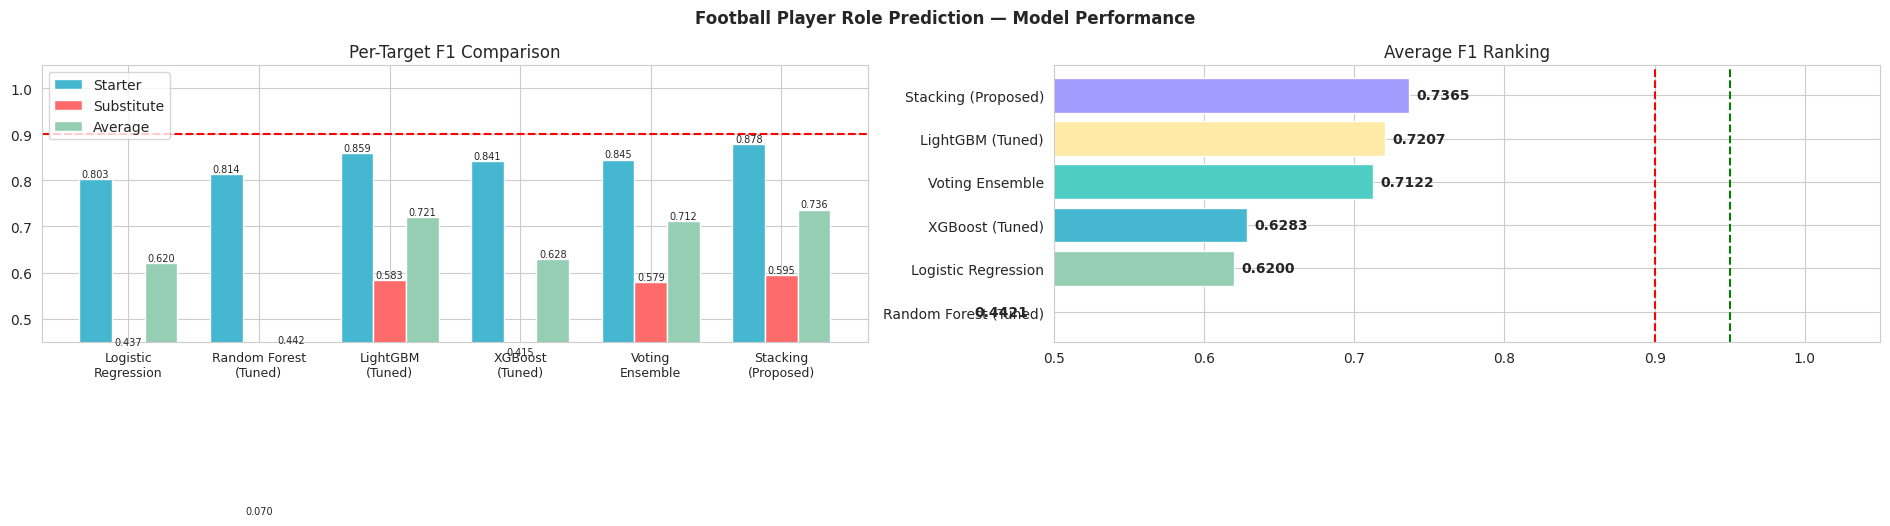

✅ Saved: model_performance_comparison.png


In [33]:
# ============================================================================
# 📊 MODEL PERFORMANCE VISUALIZATION (COMPACT VERSION)
# ============================================================================

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import f1_score

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'

# ---------------------------------------------------------------------------
# Models
# ---------------------------------------------------------------------------
model_names = [
    "Logistic\nRegression",
    "Random Forest\n(Tuned)",
    "LightGBM\n(Tuned)",
    "XGBoost\n(Tuned)",
    "Voting\nEnsemble",
    "Stacking\n(Proposed)"
]

# ---------------------------------------------------------------------------
# Helper function (🔥 key optimization)
# ---------------------------------------------------------------------------
def get_f1(pred, y_col):
    return round(f1_score(y_test[:, y_col], pred), 4)

# ---------------------------------------------------------------------------
# Predictions mapping
# ---------------------------------------------------------------------------
preds_starter = [
    lr_f1_starter,
    rf_predictions[:, 0],
    lgb_pred[:, 0],
    xgb_predictions[0],
    ensemble_pred[:, 0],
    f1_starter_stack
]

preds_sub = [
    lr_f1_sub,
    rf_predictions[:, 1],
    lgb_pred[:, 1],
    xgb_predictions[1],
    ensemble_pred[:, 1],
    f1_sub_stack
]

# ---------------------------------------------------------------------------
# Compute scores (clean loop style)
# ---------------------------------------------------------------------------
starter_f1 = [
    round(p if isinstance(p, float) else get_f1(p, 0), 4)
    for p in preds_starter
]

sub_f1 = [
    round(p if isinstance(p, float) else get_f1(p, 1), 4)
    for p in preds_sub
]

avg_f1 = [(a + b) / 2 for a, b in zip(starter_f1, sub_f1)]

# ---------------------------------------------------------------------------
# Plot setup
# ---------------------------------------------------------------------------
x = np.arange(len(model_names))
w = 0.25

fig, ax = plt.subplots(1, 2, figsize=(19, 7))
fig.suptitle("Football Player Role Prediction — Model Performance", fontweight='bold')

# ============================================================================
# 📊 1. GROUPED BAR
# ============================================================================
ax1 = ax[0]

b1 = ax1.bar(x - w, starter_f1, w, label="Starter", color="#45B7D1")
b2 = ax1.bar(x, sub_f1, w, label="Substitute", color="#FF6B6B")
b3 = ax1.bar(x + w, avg_f1, w, label="Average", color="#96CEB4")

ax1.axhline(0.90, linestyle="--", color="red")

ax1.set_xticks(x)
ax1.set_xticklabels(model_names, fontsize=9)
ax1.set_ylim(0.45, 1.05)
ax1.set_title("Per-Target F1 Comparison")
ax1.legend()

# value labels (short)
for bars in [b1, b2, b3]:
    for bar in bars:
        ax1.text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+0.005,
                 f"{bar.get_height():.3f}",
                 ha='center', fontsize=7)

# ============================================================================
# 📊 2. HORIZONTAL BAR
# ============================================================================
ax2 = ax[1]

idx = np.argsort(avg_f1)

sorted_names = [model_names[i].replace("\n", " ") for i in idx]
sorted_vals = [avg_f1[i] for i in idx]

bars = ax2.barh(sorted_names, sorted_vals,
                color=["#FF6B6B","#96CEB4","#45B7D1","#4ECDC4","#FFEAA7","#A29BFE"])

ax2.axvline(0.90, linestyle="--", color="red")
ax2.axvline(0.95, linestyle="--", color="green")

ax2.set_xlim(0.5, 1.05)
ax2.set_title("Average F1 Ranking")

for bar, v in zip(bars, sorted_vals):
    ax2.text(v+0.005, bar.get_y()+bar.get_height()/2,
             f"{v:.4f}", va='center', fontweight='bold')

plt.tight_layout()
plt.savefig("model_performance_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print("✅ Saved: model_performance_comparison.png")

Cell-27

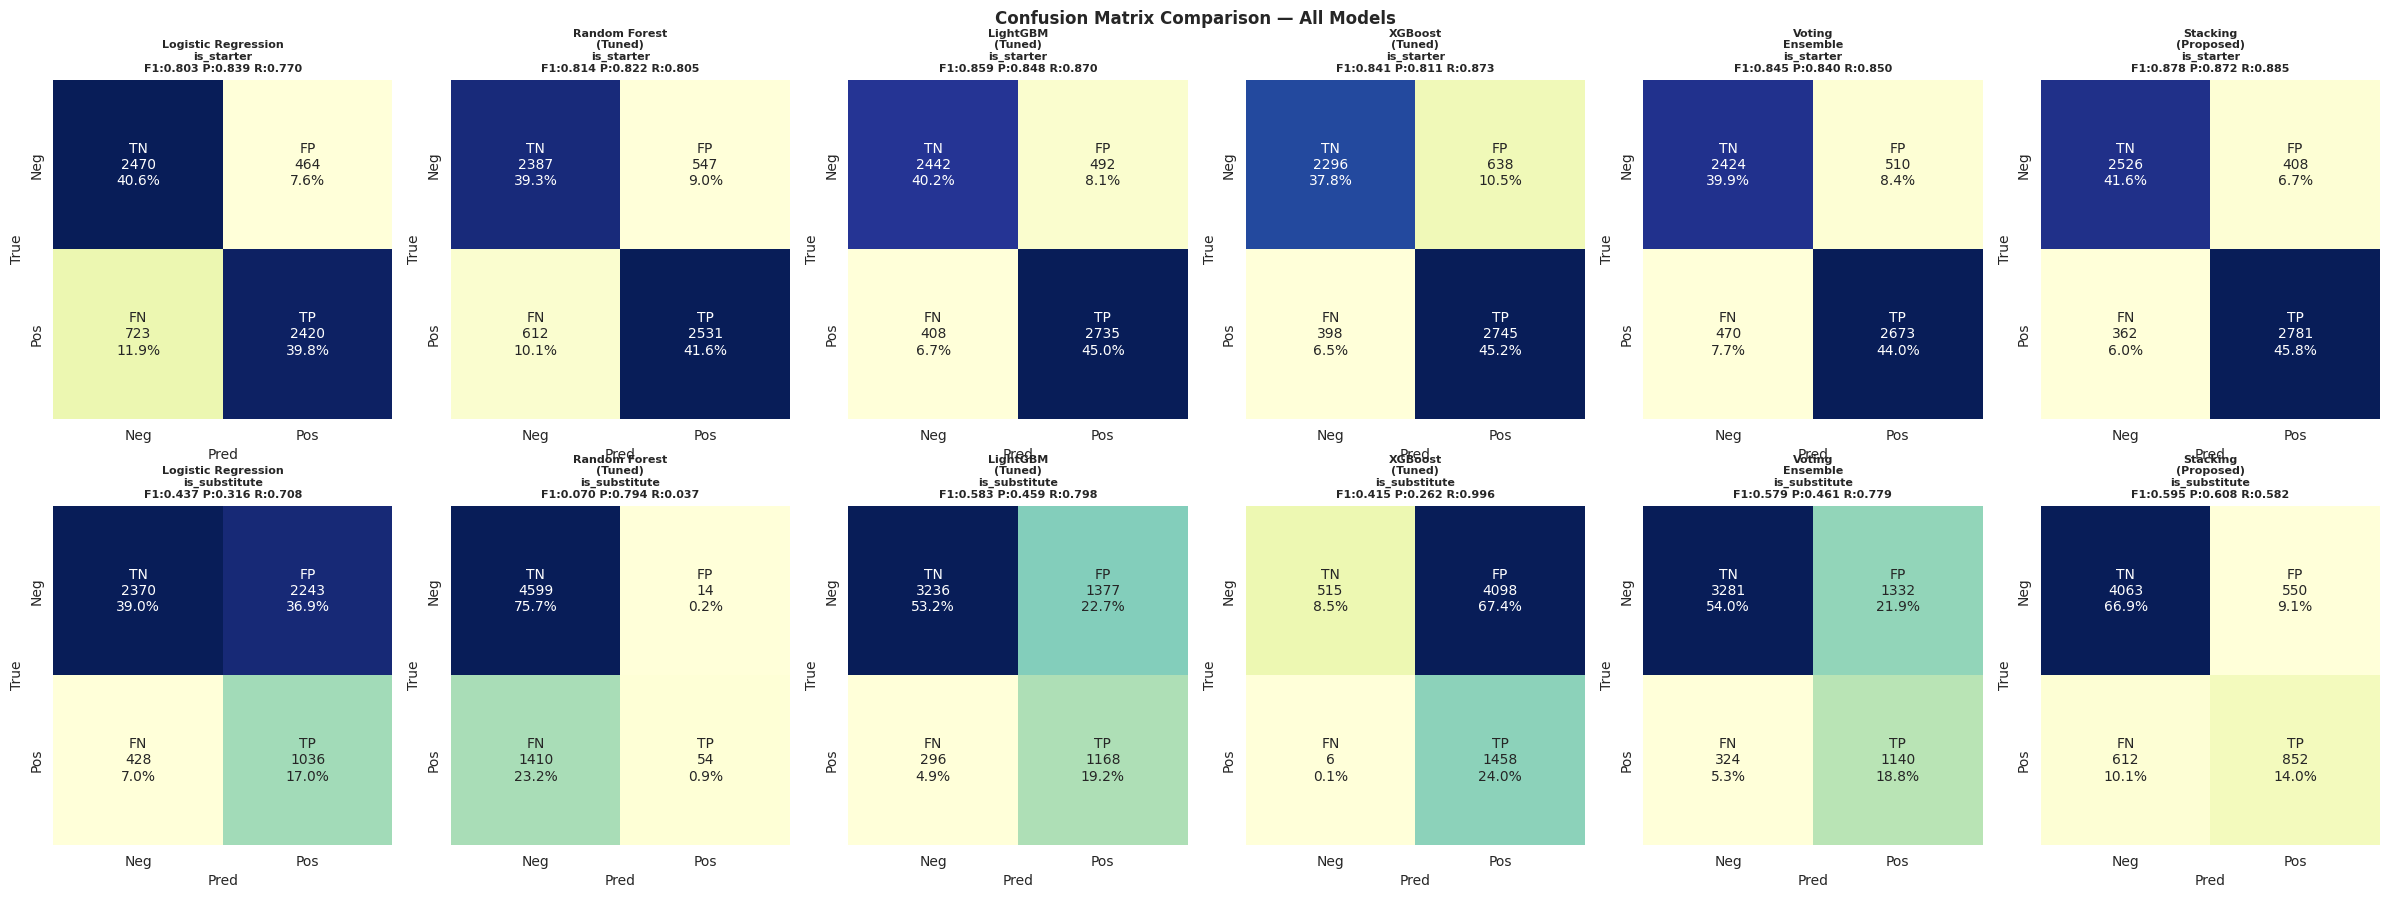

✅ Saved: all_models_confusion_matrix.png


In [34]:
# ============================================================================
# 📊 CONFUSION MATRIX — ALL MODELS (COMPACT VERSION)
# ============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'

# ---------------------------------------------------------------------------
# Models
# ---------------------------------------------------------------------------
models = {
    "Logistic Regression": lr_pred,
    "Random Forest\n(Tuned)": rf_predictions,
    "LightGBM\n(Tuned)": lgb_pred,
    "XGBoost\n(Tuned)": np.column_stack(xgb_predictions),
    "Voting\nEnsemble": ensemble_pred,
    "Stacking\n(Proposed)": np.column_stack([pred_starter, pred_substitute])
}

targets = ["is_starter", "is_substitute"]

# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, len(models), figsize=(24, 9))
fig.suptitle("Confusion Matrix Comparison — All Models", fontweight="bold")

for c, (name, pred) in enumerate(models.items()):
    for r, t in enumerate(targets):

        ax = axes[r, c]
        y_true, y_pred = y_test[:, r], pred[:, r]

        cm = confusion_matrix(y_true, y_pred)
        tn, fp, fn, tp = cm.ravel()
        total = cm.sum()

        # metrics (short)
        p = precision_score(y_true, y_pred, zero_division=0)
        rcl = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)

        # annotation
        ann = np.array([
            [f"TN\n{tn}\n{tn/total:.1%}", f"FP\n{fp}\n{fp/total:.1%}"],
            [f"FN\n{fn}\n{fn/total:.1%}", f"TP\n{tp}\n{tp/total:.1%}"]
        ])

        sns.heatmap(cm, annot=ann, fmt="", cmap="YlGnBu",
                    square=True, cbar=False,
                    xticklabels=["Neg", "Pos"],
                    yticklabels=["Neg", "Pos"],
                    ax=ax)

        ax.set_title(f"{name}\n{t}\nF1:{f1:.3f} P:{p:.3f} R:{rcl:.3f}",
                     fontsize=8, fontweight="bold")

        ax.set_xlabel("Pred")
        ax.set_ylabel("True")

plt.tight_layout()
plt.savefig("all_models_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("✅ Saved: all_models_confusion_matrix.png")

Cell-28

In [35]:
# ============================================================================
# 🔍 TRAIN vs TEST COMPARISON — OVERFITTING CHECK
# ============================================================================

from sklearn.metrics import f1_score
import numpy as np

print("\n" + "=" * 80)
print("🔍 TRAIN vs TEST COMPARISON — OVERFITTING CHECK")
print("=" * 80)

targets = ['is_starter', 'is_substitute']

# ---------------------------------------------------------------------------
# Train Predictions
# ---------------------------------------------------------------------------

lr_train = [
    lr_model.estimators_[0].predict(X_train_final),
    lr_model.estimators_[1].predict(X_train_final)
]

rf_train = rf_model.predict(X_train_final)

xgb_train = [
    xgb_models[0].predict(X_train_final),
    xgb_models[1].predict(X_train_sub_sm)   # trained on SMOTE
]

lgb_train = [
    lgb_model.estimators_[0].predict(X_train_final),
    lgb_model.estimators_[1].predict(X_train_final)
]

# ---------------------------------------------------------------------------
# Model Configurations
# ---------------------------------------------------------------------------

models = [

    ("Logistic Regression", lr_train, lr_pred),

    ("Random Forest (Tuned)",
     [rf_train[:, 0], rf_train[:, 1]],
     rf_predictions),

    ("XGBoost (Tuned)",
     xgb_train,
     np.column_stack([xgb_predictions[0], xgb_predictions[1]])),

    ("LightGBM (Tuned)",
     lgb_train,
     lgb_pred)
]

print(f"\n{'Model':<28} {'Target':<16} {'Train F1':>9} {'Test F1':>9} {'Diff':>8} {'Status':>15}")
print("-" * 90)

# ---------------------------------------------------------------------------
# Overfitting Analysis
# ---------------------------------------------------------------------------

for model_name, train_pred, test_pred in models:

    for i, target in enumerate(targets):

        # XGBoost substitute uses SMOTE labels
        if model_name == "XGBoost (Tuned)" and i == 1:
            train_f1 = round(
                f1_score(y_train_sub_sm, train_pred[i]),
                4
            )
        else:
            train_f1 = round(
                f1_score(y_train[:, i], train_pred[i]),
                4
            )

        test_f1 = round(
            f1_score(y_test[:, i], test_pred[:, i]),
            4
        )

        diff = round(train_f1 - test_f1, 4)

        if diff <= 0.05:
            status = "✅ Good Fit"
        elif diff <= 0.15:
            status = "⚠️ Overfit Risk"
        else:
            status = "🔥 Severe Overfit"

        print(f"{model_name:<28} {target:<16} {train_f1:>9.4f} {test_f1:>9.4f} {diff:>8.4f} {status:>15}")

    print()

print("Stacking Ensemble → Uses internal CV (not directly comparable)")

print("\n" + "=" * 80)
print("✅ Overfitting Check Complete!")
print("=" * 80)


🔍 TRAIN vs TEST COMPARISON — OVERFITTING CHECK

Model                        Target            Train F1   Test F1     Diff          Status
------------------------------------------------------------------------------------------
Logistic Regression          is_starter          0.8002    0.8031  -0.0029      ✅ Good Fit
Logistic Regression          is_substitute       0.4297    0.4369  -0.0072      ✅ Good Fit

Random Forest (Tuned)        is_starter          0.8140    0.8137   0.0003      ✅ Good Fit
Random Forest (Tuned)        is_substitute       0.0653    0.0705  -0.0052      ✅ Good Fit

XGBoost (Tuned)              is_starter          0.8461    0.8413   0.0048      ✅ Good Fit
XGBoost (Tuned)              is_substitute       0.6919    0.4154   0.2765 🔥 Severe Overfit

LightGBM (Tuned)             is_starter          0.8661    0.8587   0.0074      ✅ Good Fit
LightGBM (Tuned)             is_substitute       0.6124    0.5827   0.0297      ✅ Good Fit

Stacking Ensemble → Uses internal CV

Cell-29

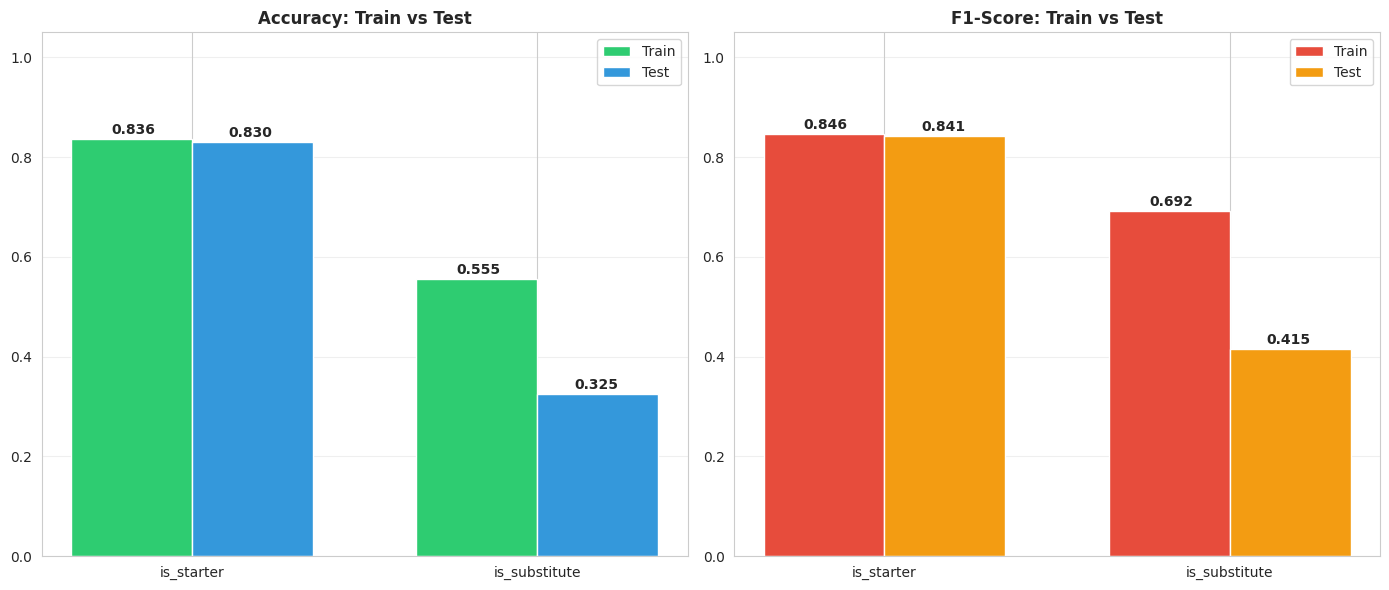


📊 OVERFITTING SUMMARY

is_starter:
  Train data: (24305, 15) | Test data: (6077, 15)
  Accuracy Diff: 0.0064
  F1 Diff      : 0.0048
  Status       : ✅ Good Fit

is_substitute:
  Train data: (36896, 15) | Test data: (6077, 15)
  Accuracy Diff: 0.2306
  F1 Diff      : 0.2765
  Status       : 🔥 Severe Overfit

✅ Done!


In [36]:
# Train vs Test Comparison — FIXED per-target feature sets

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

target_names = ['is_starter', 'is_substitute']
train_accs, test_accs = [], []
train_f1s,  test_f1s  = [], []

# Correct train/test sets per target
train_sets = [
    (X_train_starter, y_train[:, 0]),  # i=0: starter
    (X_train_sub_sm,  y_train_sub_sm)  # i=1: substitute (SMOTE)
]
test_sets = [
    (X_test_starter,  y_test[:, 0]),   # i=0
    (X_test_sub,      y_test[:, 1])    # i=1
]

for i in range(2):
    X_tr, y_tr = train_sets[i]
    X_te, y_te = test_sets[i]

    y_train_pred = xgb_models[i].predict(X_tr)
    y_test_pred  = xgb_models[i].predict(X_te)

    train_accs.append(accuracy_score(y_tr, y_train_pred))
    test_accs.append(accuracy_score(y_te, y_test_pred))
    train_f1s.append(f1_score(y_tr, y_train_pred))
    test_f1s.append(f1_score(y_te, y_test_pred))

# ── Visualization ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
x = np.arange(len(target_names))
width = 0.35

# Accuracy
axes[0].bar(x - width/2, train_accs, width, label='Train', color='#2ecc71')
axes[0].bar(x + width/2, test_accs,  width, label='Test',  color='#3498db')
axes[0].set_title('Accuracy: Train vs Test', fontweight='bold')
axes[0].set_xticks(x); axes[0].set_xticklabels(target_names)
axes[0].set_ylim(0.0, 1.05); axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
for i in range(2):
    axes[0].text(i - 0.17, train_accs[i]+0.01, f'{train_accs[i]:.3f}', ha='center', fontweight='bold')
    axes[0].text(i + 0.17, test_accs[i]+0.01,  f'{test_accs[i]:.3f}',  ha='center', fontweight='bold')

# F1
axes[1].bar(x - width/2, train_f1s, width, label='Train', color='#e74c3c')
axes[1].bar(x + width/2, test_f1s,  width, label='Test',  color='#f39c12')
axes[1].set_title('F1-Score: Train vs Test', fontweight='bold')
axes[1].set_xticks(x); axes[1].set_xticklabels(target_names)
axes[1].set_ylim(0.0, 1.05); axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
for i in range(2):
    axes[1].text(i - 0.17, train_f1s[i]+0.01, f'{train_f1s[i]:.3f}', ha='center', fontweight='bold')
    axes[1].text(i + 0.17, test_f1s[i]+0.01,  f'{test_f1s[i]:.3f}',  ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# ── Overfitting Summary ────────────────────────────────────────
print("\n" + "=" * 80)
print("📊 OVERFITTING SUMMARY")
print("=" * 80)

for i in range(2):
    diff_acc = train_accs[i] - test_accs[i]
    diff_f1  = train_f1s[i]  - test_f1s[i]
    diff = max(diff_acc, diff_f1)

    if diff <= 0.05:   status = "✅ Good Fit"
    elif diff <= 0.15: status = "⚠️ Overfit Risk"
    else:              status = "🔥 Severe Overfit"

    print(f"\n{target_names[i]}:")
    print(f"  Train data: {train_sets[i][0].shape} | Test data: {test_sets[i][0].shape}")
    print(f"  Accuracy Diff: {diff_acc:.4f}")
    print(f"  F1 Diff      : {diff_f1:.4f}")
    print(f"  Status       : {status}")

print("\n✅ Done!")

Cell-30

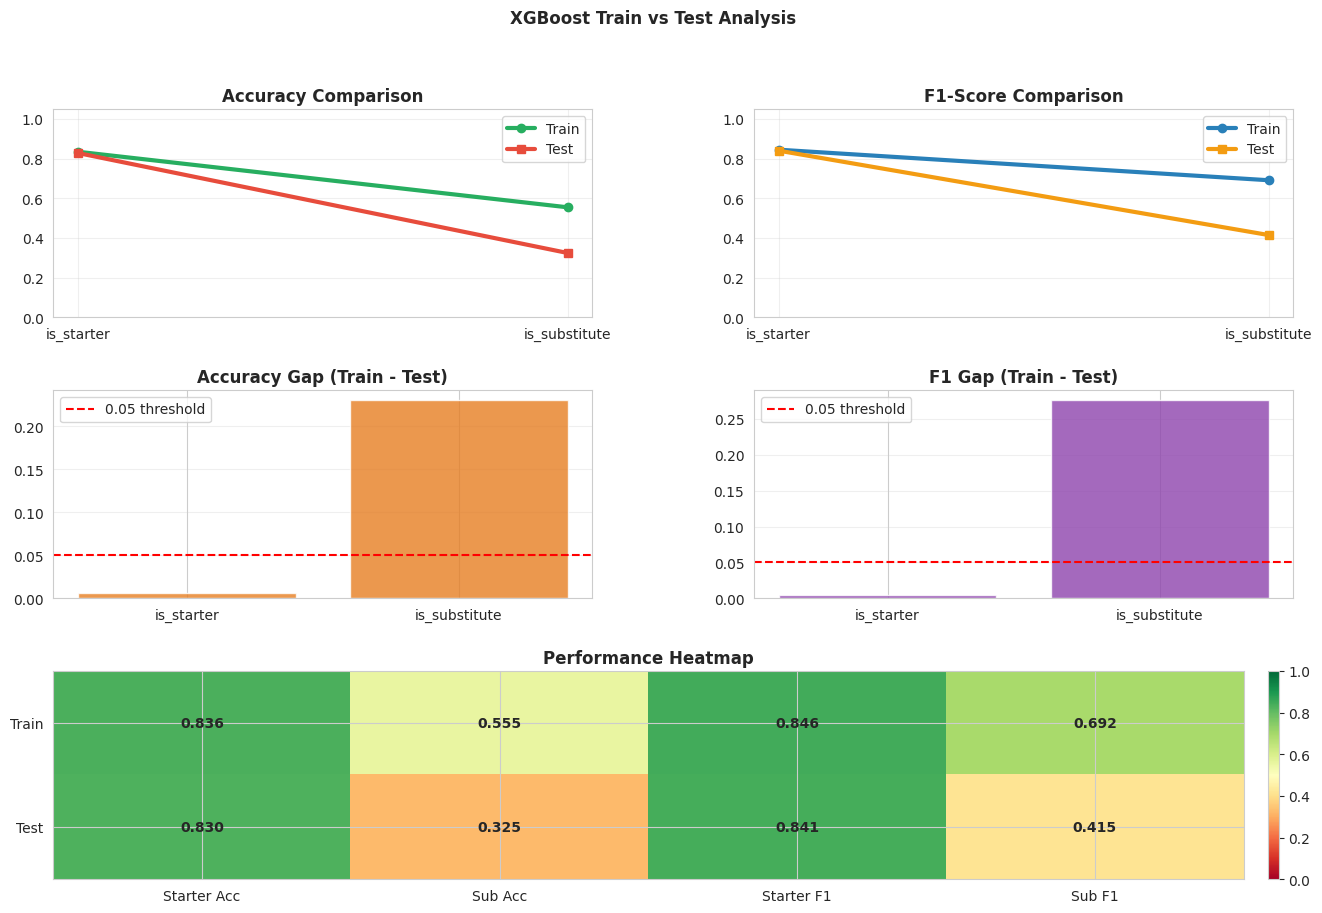

In [37]:
# ============================================================================
# 📊 TRAIN vs TEST COMPARISON - ALTERNATIVE VISUALIZATION (FIXED)
# ============================================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

target_names = ['is_starter', 'is_substitute']

train_accs, test_accs = [], []
train_f1s, test_f1s = [], []

for i in range(2):

    if i == 0:
        X_train_use = X_train_starter
        X_test_use  = X_test_starter
        y_train_use = y_train[:, 0]
        y_test_use  = y_test[:, 0]
    else:
        X_train_use = X_train_sub_sm
        X_test_use  = X_test_sub
        y_train_use = y_train_sub_sm
        y_test_use  = y_test[:, 1]

    y_train_pred = xgb_models[i].predict(X_train_use)
    y_test_pred  = xgb_models[i].predict(X_test_use)

    train_accs.append(accuracy_score(y_train_use, y_train_pred))
    test_accs.append(accuracy_score(y_test_use, y_test_pred))
    train_f1s.append(f1_score(y_train_use, y_train_pred))
    test_f1s.append(f1_score(y_test_use, y_test_pred))

# --------------------------------------------------------------------
# Figure setup
# --------------------------------------------------------------------
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.3)

x_pos = np.arange(len(target_names))

# ============================================================================
# 1. Accuracy Line Plot
# ============================================================================
ax1 = fig.add_subplot(gs[0, 0])

ax1.plot(x_pos, train_accs, 'o-', label='Train', linewidth=3, color='#27ae60')
ax1.plot(x_pos, test_accs, 's-', label='Test', linewidth=3, color='#e74c3c')

ax1.set_xticks(x_pos)
ax1.set_xticklabels(target_names)
ax1.set_title('Accuracy Comparison', fontweight='bold')
ax1.set_ylim(0, 1.05)
ax1.legend()
ax1.grid(alpha=0.3)

# ============================================================================
# 2. F1 Line Plot
# ============================================================================
ax2 = fig.add_subplot(gs[0, 1])

ax2.plot(x_pos, train_f1s, 'o-', label='Train', linewidth=3, color='#2980b9')
ax2.plot(x_pos, test_f1s, 's-', label='Test', linewidth=3, color='#f39c12')

ax2.set_xticks(x_pos)
ax2.set_xticklabels(target_names)
ax2.set_title('F1-Score Comparison', fontweight='bold')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(alpha=0.3)

# ============================================================================
# 3. Accuracy Gap
# ============================================================================
ax3 = fig.add_subplot(gs[1, 0])

acc_diff = np.array(train_accs) - np.array(test_accs)

ax3.bar(x_pos, acc_diff, color='#e67e22', alpha=0.8)
ax3.axhline(0.05, linestyle='--', color='red', label='0.05 threshold')

ax3.set_xticks(x_pos)
ax3.set_xticklabels(target_names)
ax3.set_title('Accuracy Gap (Train - Test)', fontweight='bold')
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# ============================================================================
# 4. F1 Gap
# ============================================================================
ax4 = fig.add_subplot(gs[1, 1])

f1_diff = np.array(train_f1s) - np.array(test_f1s)

ax4.bar(x_pos, f1_diff, color='#8e44ad', alpha=0.8)
ax4.axhline(0.05, linestyle='--', color='red', label='0.05 threshold')

ax4.set_xticks(x_pos)
ax4.set_xticklabels(target_names)
ax4.set_title('F1 Gap (Train - Test)', fontweight='bold')
ax4.legend()
ax4.grid(axis='y', alpha=0.3)

# ============================================================================
# 5. Heatmap
# ============================================================================
ax5 = fig.add_subplot(gs[2, :])

metrics = np.array([
    train_accs + train_f1s,
    test_accs + test_f1s
])

im = ax5.imshow(metrics, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')

ax5.set_xticks(np.arange(4))
ax5.set_xticklabels(['Starter Acc', 'Sub Acc', 'Starter F1', 'Sub F1'])
ax5.set_yticks([0, 1])
ax5.set_yticklabels(['Train', 'Test'])
ax5.set_title('Performance Heatmap', fontweight='bold')

for i in range(2):
    for j in range(4):
        ax5.text(j, i, f'{metrics[i, j]:.3f}', ha='center', va='center', fontweight='bold')

plt.colorbar(im, ax=ax5, fraction=0.02, pad=0.02)
plt.suptitle('XGBoost Train vs Test Analysis', fontweight='bold')
plt.show()

# User Interface

In [38]:
import pandas as pd
import numpy as np

# =========================================================
# 1. CORRECT SOURCE DATA
# =========================================================
df = final_merged.copy()  # ← এটাই আসল player data

# Column names already confirmed from debug
team_col     = 'C_name'
position_col = 'PS'
player_col   = 'P_name'
rating_col   = 'Rating' if 'Rating' in df.columns else None
goal_col     = 'Goals'  if 'Goals'  in df.columns else None
assist_col   = 'Assist' if 'Assist' in df.columns else None
date_col     = 'Date'   if 'Date'   in df.columns else None

print("✅ Data loaded from final_merged")
print(f"Shape: {df.shape}")
print(f"Columns detected → team: {team_col}, pos: {position_col}, player: {player_col}")

# =========================================================
# 2. CONFIG
# =========================================================
pos_map = {'G': 'GK', 'D': 'DEF', 'M': 'MID', 'F': 'FWD'}

team_fix_map = {
    'Leiceste': 'Leicester', 'Leicester': 'Leicester',
    'Man Utd ': 'Man Utd',   'Man Utd':   'Man Utd',
    'Man City':  'Man City'
}

real_managers = {
    'Arsenal': 'Mikel Arteta', 'Aston Villa': 'Unai Emery',
    'Bournemouth': 'Andoni Iraola', 'Brentford': 'Thomas Frank',
    'Brighton': 'Fabian Hürzeler', 'Chelsea': 'Enzo Maresca',
    'Crystal Palace': 'Oliver Glasner', 'Everton': 'Sean Dyche',
    'Fulham': 'Marco Silva', 'Ipswich': 'Kieran McKenna',
    'Leicester': 'Steve Cooper', 'Liverpool': 'Arne Slot',
    'Man City': 'Pep Guardiola', 'Man Utd': 'Rúben Amorim',
    'Newcastle': 'Eddie Howe', 'Nottingham Forest': 'Nuno Espírito Santo',
    'Southampton': 'Russell Martin', 'Tottenham': 'Ange Postecoglou',
    'West Ham': 'Julen Lopetegui', 'Wolves': "Gary O'Neil"
}

def clean_team_name(t):
    return team_fix_map.get(str(t).strip(), str(t).strip())

def get_player_category(pos):
    return pos_map.get(str(pos).strip().upper(), 'OTHER')

def get_recent_form(player_name, n=3):
    p_data = df[df[player_col] == player_name].copy()
    if date_col: p_data = p_data.sort_values(date_col, ascending=False)
    p_data = p_data.head(n)
    if p_data.empty or rating_col not in p_data.columns: return "-"
    vals = []
    for r in p_data[rating_col]:
        try: vals.append(f"{float(r):.1f}")
        except: vals.append("-")
    return " | ".join(vals[::-1])

def print_squad_section(title, squad_df, is_starter=True):
    print("\n" + "═"*130)
    print(f"  {title}")
    print("═"*130)
    print(f"  {'POS':<8} {'PLAYER NAME':<25} {'GOALS':<8} {'ASSISTS':<10} {'LAST 3 RTG':<22} {'AVG RTG':<9} {'CONFIDENCE'}")
    print("  " + "─"*125)

    for cat in ['GK', 'DEF', 'MID', 'FWD']:
        subset = squad_df[squad_df['Category'] == cat]
        if subset.empty: continue
        for _, p in subset.iterrows():
            p_stats = df[df[player_col] == p[player_col]]
            goals   = int(p_stats[goal_col].sum())   if goal_col and goal_col in p_stats.columns else 0
            assists = int(p_stats[assist_col].sum())  if assist_col and assist_col in p_stats.columns else 0
            form    = get_recent_form(p[player_col], n=3)
            avg_rtg = round(float(p_stats[rating_col].mean()), 2) if rating_col and rating_col in p_stats.columns else "-"

            score   = p['Starter_Score'] if is_starter else p['Sub_Score']
            bar     = "█" * int(score * 5) + "░" * (5 - int(score * 5))
            icon    = "⭐" if is_starter else "🔄"

            print(f"  {str(p[position_col]):<8} {str(p[player_col]):<25} {goals:<8} {assists:<10} {form:<22} {str(avg_rtg):<9} {bar} {int(score*100)}% {icon}")
    print("═"*130)

# =========================================================
# 3. XGBoost feature lists (auto-detected from trained models)
# =========================================================
starter_features = xgb_models[0].get_booster().feature_names  # X_train_starter features
sub_features     = xgb_models[1].get_booster().feature_names   # X_train_sub features

print(f"\nStarter features ({len(starter_features)}): {starter_features}")
print(f"Sub features     ({len(sub_features)}): {sub_features}")

# =========================================================
# 4. Input preparation + feature alignment
# =========================================================
def prepare_single_player_input(row_df, manager_name, feature_list):
    data = row_df.copy()
    data['Managers'] = manager_name

    # Label encoding
    for col in label_encoders:
        if col in data.columns:
            data[col] = data[col].fillna('missing').astype(str).apply(
                lambda x: label_encoders[col].transform([x])[0]
                if x in label_encoders[col].classes_ else -1
            )

    # Add missing numerical columns
    for col in scaler.feature_names_in_:
        if col not in data.columns:
            data[col] = 0

    # Scale
    data[scaler.feature_names_in_] = scaler.transform(data[scaler.feature_names_in_])

    # Feature align + order fix for XGBoost
    for col in feature_list:
        if col not in data.columns:
            data[col] = 0
    aligned = data[feature_list]  # exact order XGBoost expects
    return aligned

# =========================================================
# 5. TEAM LIST
# =========================================================
raw_teams    = df[team_col].dropna().astype(str).unique()
unique_teams = sorted(list(set([clean_team_name(t) for t in raw_teams])))

print("\n" + "="*80)
print(f"⚽ AVAILABLE TEAMS (Total: {len(unique_teams)})")
print("="*80)
print(f"{'ID':<5} {'TEAM NAME':<25} {'MANAGER'}")
print("-"*80)
for i, team in enumerate(unique_teams):
    print(f"{i+1:<5} {team:<25} {real_managers.get(team, 'Unknown')}")

# =========================================================
# 6. MAIN LOOP
# =========================================================
while True:
    print("\n" + "="*60)
    print("🎯 SQUAD SELECTION SYSTEM  (type 'quit' to exit)")
    print("="*60)

    t_input = input("📝 Team Name or ID: ").strip()
    if t_input.lower() == 'quit': break

    if t_input.isdigit() and 1 <= int(t_input) <= len(unique_teams):
        selected_team = unique_teams[int(t_input) - 1]
    else:
        selected_team = clean_team_name(t_input)

    if selected_team not in unique_teams:
        print("❌ Invalid Team!")
        continue

    selected_manager = input("📝 Manager Name: ").strip()

    # Formation input
    print("\n📋 STARTING XI FORMATION (Total must = 11)")
    try:
        sx_gk, sx_def, sx_mid, sx_fwd = (
            int(input("  GK : ")), int(input("  DEF: ")),
            int(input("  MID: ")), int(input("  FWD: "))
        )
        total = sx_gk + sx_def + sx_mid + sx_fwd
        if total != 11: print(f"⚠️ Total = {total} (not 11)")
    except:
        sx_gk, sx_def, sx_mid, sx_fwd = 1, 4, 4, 2
        print("⚠️ Defaulting to 1-4-4-2")

    # Get team players (latest record per player)
    variations = [k for k, v in team_fix_map.items() if v == selected_team] + [selected_team]
    team_df = df[df[team_col].astype(str).str.strip().isin(variations)].copy()
    team_df = team_df.sort_values(date_col, ascending=False) if date_col else team_df
    team_df = team_df.drop_duplicates(subset=[player_col])

    if team_df.empty:
        print("❌ No players found!")
        continue

    print(f"\n  🔍 Found {len(team_df)} players for {selected_team}")

    # Prepare inputs separately for starter and sub models
    starter_input = prepare_single_player_input(team_df, selected_manager, starter_features)
    sub_input     = prepare_single_player_input(team_df, selected_manager, sub_features)

    team_df = team_df.reset_index(drop=True)
    team_df['Starter_Score'] = xgb_models[0].predict_proba(starter_input)[:, 1]
    team_df['Sub_Score']     = xgb_models[1].predict_proba(sub_input)[:, 1]
    team_df['Category']      = team_df[position_col].apply(get_player_category)

    # Select Starting XI
    start_xi = pd.concat([
        team_df[team_df['Category'] == 'GK'].sort_values('Starter_Score', ascending=False).head(sx_gk),
        team_df[team_df['Category'] == 'DEF'].sort_values('Starter_Score', ascending=False).head(sx_def),
        team_df[team_df['Category'] == 'MID'].sort_values('Starter_Score', ascending=False).head(sx_mid),
        team_df[team_df['Category'] == 'FWD'].sort_values('Starter_Score', ascending=False).head(sx_fwd),
    ])

    print_squad_section(
        f"🏆 STARTING XI | {selected_team.upper()} | {sx_gk}-{sx_def}-{sx_mid}-{sx_fwd}",
        start_xi, is_starter=True
    )

    # Substitute input
    print("\n🔄 SUBSTITUTE FORMATION")
    try:
        sb_gk, sb_def, sb_mid, sb_fwd = (
            int(input("  GK : ")), int(input("  DEF: ")),
            int(input("  MID: ")), int(input("  FWD: "))
        )
    except:
        sb_gk, sb_def, sb_mid, sb_fwd = 0, 1, 1, 1

    remaining = team_df.drop(start_xi.index)
    subs = pd.concat([
        remaining[remaining['Category'] == 'GK'].sort_values('Sub_Score', ascending=False).head(sb_gk),
        remaining[remaining['Category'] == 'DEF'].sort_values('Sub_Score', ascending=False).head(sb_def),
        remaining[remaining['Category'] == 'MID'].sort_values('Sub_Score', ascending=False).head(sb_mid),
        remaining[remaining['Category'] == 'FWD'].sort_values('Sub_Score', ascending=False).head(sb_fwd),
    ])

    print_squad_section(f"⚡ SUBSTITUTES ({len(subs)} Players)", subs, is_starter=False)
    print("\n✅ Done! Next team or 'quit' to exit.")

✅ Data loaded from final_merged
Shape: (30382, 54)
Columns detected → team: C_name, pos: PS, player: P_name

Starter features (15): ['TD_win', 'NT', 'PS', 'C_name', 'OC_name', 'T2', 'GC', 'Match played', 'T1', 'GS', 'GD', 'Points', 'Lose', 'Managers', 'Win']
Sub features     (15): ['NT', 'TD_win', 'PS', 'OC_name', 'C_name', 'T2', 'Match played', 'GC', 'GS', 'T1', 'GD', 'Points', 'Lose', 'Managers', 'Win']

⚽ AVAILABLE TEAMS (Total: 21)
ID    TEAM NAME                 MANAGER
--------------------------------------------------------------------------------
1     Arsenal                   Mikel Arteta
2     Aston Villa               Unai Emery
3     Bournemouth               Andoni Iraola
4     Brentford                 Thomas Frank
5     Brighton                  Fabian Hürzeler
6     Chelsea                   Enzo Maresca
7     Crystal Palace            Oliver Glasner
8     Everton                   Sean Dyche
9     Fulham                    Marco Silva
10    Ipswich                   K

In [39]:
import pickle
import os

# ডিরেক্টরি তৈরি করা (যদি না থাকে)
save_dir = '/content/drive/MyDrive/Football/deployed_models/'
os.makedirs(save_dir, exist_ok=True)

# ১. স্কেলার এবং এনকোডার সংরক্ষণ
with open(os.path.join(save_dir, 'scaler.pkl'), 'wb') as f:
    pickle.dump(scaler, f)

with open(os.path.join(save_dir, 'label_encoders.pkl'), 'wb') as f:
    pickle.dump(label_encoders, f)

# ২. সেরা মডেল (Stacking Ensemble) সংরক্ষণ
with open(os.path.join(save_dir, 'stack_starter.pkl'), 'wb') as f:
    pickle.dump(stack_starter, f)

with open(os.path.join(save_dir, 'stack_substitute.pkl'), 'wb') as f:
    pickle.dump(stack_substitute, f)

print("=========================================================")
print("✅ All deployment artifacts successfully saved to Google Drive!")
print("=========================================================")
print(f"Saved files in: {save_dir}")
print("1. scaler.pkl")
print("2. label_encoders.pkl")
print("3. stack_starter.pkl")
print("4. stack_substitute.pkl")

✅ All deployment artifacts successfully saved to Google Drive!
Saved files in: /content/drive/MyDrive/Football/deployed_models/
1. scaler.pkl
2. label_encoders.pkl
3. stack_starter.pkl
4. stack_substitute.pkl
